# Hearing the Shape of a Drum — A Gentle Introduction to `NDArray`

Why does a plucked **guitar string** play a clear musical note, while a struck **drum** makes a percussive *"boom"*? And if you close your eyes and only **listen** to a drum, can you tell what shape it is?

In 1966, mathematician **Mark Kac** asked this exact question in a famous paper titled *"Can One Hear the Shape of a Drum?"*

In this tutorial, we'll answer that question step by step—starting from a simple 1D guitar string and building up to 2D drums of different shapes—while learning **`package:ndarray`** from the ground up:

1. **Creating 1D arrays & vectorized math (`linspace`, `sin`, `Plot`, `Audio`):** Plot waves and listen to pure tones.
2. **Comparing neighbors without loops (`Slice`):** Understand how tension pulls a stretched string back toward flat.
3. **Building matrices from diagonals (`NDArray.ones`, `diag`, `Table`, `Heatmap`):** Turn the "neighbor pull" rule into a matrix.
4. **Finding natural vibration modes (`eigh`, `Index`):** Discover why a guitar string vibrates at whole-number harmonic frequencies ($1f, 2f, 3f, \dots$).
5. **Stepping up to a 2D Square Drum (`NDArray.eye`, `kron`, `reshape`, `Image`):** Combine horizontal and vertical strings into a 2D grid and draw **Chladni sand patterns**.
6. **Carving out Circular & L-Shaped Drums (`ogrid`, `logicalAnd`, `Mask`):** Use 2D boolean masks to study any drum shape.
7. **Hearing the area & sound of a drum (`Animation`, `Audio`, `Spectrogram`, `rfft`):** Watch a wave bounce around an L-shaped drum and synthesize real drum sounds!

## Step 1: 1D Arrays & Vectorized Math (`linspace` and `sin`)

Before simulating physics, let's create our first `NDArray`.

Suppose a guitar string is stretched between $x = 0$ and $x = 1$. To represent the string on a computer, we sample it at evenly spaced points using **`linspace(start, stop, count)`**.

Once we have an array `x`, we don't need a `for` loop to compute a sine wave at every point. Passing `x` to **`sin(...)`** or multiplying it by a number automatically applies the operation to **every element at once** in fast native C code (this is called *vectorization*).

In [1]:
// Create 60 evenly spaced points from x = 0.0 to x = 1.0
final NDArray<Float64> xString = linspace(0.0, 1.0, 60, dtype: DType.float64);

// Compute the first two standing-wave shapes of a guitar string (no loops!)
final NDArray<Float64> mode1 = sin(xString * math.pi);       // 1 arch  (fundamental)
final NDArray<Float64> mode2 = sin(xString * (2 * math.pi)); // 2 arches (first overtone)

display(Plot(
  x: xString,
  y: mode1,
  title: 'Guitar String Mode 1: Fundamental Wave sin(πx)',
  color: '#89b4fa',
));
Plot(
  x: xString,
  y: mode2,
  title: 'Guitar String Mode 2: Second Harmonic sin(2πx) — Stationary Node at x = 0.5',
  color: '#a6e3a1',
)

[{"mimeType":"text/html","data":"<div class=\"plot-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif;\">\n  <div style=\"font-weight: bold; margin-bottom: 8px; color: #cdd6f4; font-size: 1.1em;\">Guitar String Mode 1: Fundamental Wave sin(πx)</div>\n  <svg width=\"500.0\" height=\"280.0\" viewBox=\"0 0 500.0 280.0\" style=\"overflow: visible;\">\n    <line x1=\"40.0\" y1=\"240.0\" x2=\"460.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <line x1=\"40.0\" y1=\"40.0\" x2=\"40.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <polyline fill=\"none\" stroke=\"#89b4fa\" stroke-width=\"2.5\" points=\"40.0,240.0 47.1,229.4 54.2,218.7 61.4,208.2 68.5,197.7 75.6,187.4 82.7,177.2 89.8,167.1 96.9,157.3 104.1,147.7 111.2,138.4 118.3,129.4 125.4,120.7 132.5,112.3 139.7,104.3 146.8,96.7 153.9,89.4 161.0,82.6 168.1,76.3 175.3,70.4 182.4,65.0 189.5,60.1 196.6,55.7 203.7,51.8 210.8,48.4 218.0,45.6 225.1,43.4 232.2,41.7 239.3,40.6 246.4,40.0 253.6,40.0 260.7,40.6 267.8,41.7 274.9,43.4 282.0,45.6 289.2,48.4 296.3,51.8 303.4,55.7 310.5,60.1 317.6,65.0 324.7,70.4 331.9,76.3 339.0,82.6 346.1,89.4 353.2,96.7 360.3,104.3 367.5,112.3 374.6,120.7 381.7,129.4 388.8,138.4 395.9,147.7 403.1,157.3 410.2,167.1 417.3,177.2 424.4,187.4 431.5,197.7 438.6,208.2 445.8,218.7 452.9,229.4 460.0,240.0\"/>\n    <text x=\"40.0\" y=\"270.0\" fill=\"#a6adc8\" font-size=\"12\">0.00</text>\n    <text x=\"460.0\" y=\"270.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">1.00</text>\n    <text x=\"30.0\" y=\"240.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">0.00</text>\n    <text x=\"30.0\" y=\"50.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">1.00</text>\n  </svg>\n</div>\n"},{"mimeType":"text/html","data":"<div class=\"plot-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif;\">\n  <div style=\"font-weight: bold; margin-bottom: 8px; color: #cdd6f4; font-size: 1.1em;\">Guitar String Mode 2: Second Harmonic sin(2πx) — Stationary Node at x = 0.5</div>\n  <svg width=\"500.0\" height=\"280.0\" viewBox=\"0 0 500.0 280.0\" style=\"overflow: visible;\">\n    <line x1=\"40.0\" y1=\"240.0\" x2=\"460.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <line x1=\"40.0\" y1=\"40.0\" x2=\"40.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <polyline fill=\"none\" stroke=\"#a6e3a1\" stroke-width=\"2.5\" points=\"40.0,140.0 47.1,129.4 54.2,118.9 61.4,108.6 68.5,98.7 75.6,89.2 82.7,80.3 89.8,72.1 96.9,64.7 104.1,58.1 111.2,52.5 118.3,47.8 125.4,44.2 132.5,41.7 139.7,40.3 146.8,40.0 153.9,40.8 161.0,42.8 168.1,45.9 175.3,50.0 182.4,55.2 189.5,61.3 196.6,68.3 203.7,76.2 210.8,84.7 218.0,93.9 225.1,103.6 232.2,113.7 239.3,124.1 246.4,134.7 253.6,145.3 260.7,155.9 267.8,166.3 274.9,176.4 282.0,186.1 289.2,195.3 296.3,203.8 303.4,211.7 310.5,218.7 317.6,224.8 324.7,230.0 331.9,234.1 339.0,237.2 346.1,239.2 353.2,240.0 360.3,239.7 367.5,238.3 374.6,235.8 381.7,232.2 388.8,227.5 395.9,221.9 403.1,215.3 410.2,207.9 417.3,199.7 424.4,190.8 431.5,181.3 438.6,171.4 445.8,161.1 452.9,150.6 460.0,140.0\"/>\n    <text x=\"40.0\" y=\"270.0\" fill=\"#a6adc8\" font-size=\"12\">0.00</text>\n    <text x=\"460.0\" y=\"270.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">1.00</text>\n    <text x=\"30.0\" y=\"240.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">-1.00</text>\n    <text x=\"30.0\" y=\"50.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">1.00</text>\n  </svg>\n</div>\n"}]

[{"mimeType":"text/html","data":"<div class=\"plot-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif;\">\n  <div style=\"font-weight: bold; margin-bottom: 8px; color: #cdd6f4; font-size: 1.1em;\">Guitar String Mode 1: Fundamental Wave sin(πx)</div>\n  <svg width=\"500.0\" height=\"280.0\" viewBox=\"0 0 500.0 280.0\" style=\"overflow: visible;\">\n    <line x1=\"40.0\" y1=\"240.0\" x2=\"460.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <line x1=\"40.0\" y1=\"40.0\" x2=\"40.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <polyline fill=\"none\" stroke=\"#89b4fa\" stroke-width=\"2.5\" points=\"40.0,240.0 47.1,229.4 54.2,218.7 61.4,208.2 68.5,197.7 75.6,187.4 82.7,177.2 89.8,167.1 96.9,157.3 104.1,147.7 111.2,138.4 118.3,129.4 125.4,120.7 132.5,112.3 139.7,104.3 146.8,96.7 153.9,89.4 161.0,82.6 168.1,76.3 175.3,70.4 182.4,65.0 189.5,60.1 196.6,55.7 203.7,51.8 210.8,48.4 218.0,45.6 225.1,43.4 232.2,41.7 239.3,40.6 246.4,40.0 253.6,40.0 260.7,40.6 267.8,41.7 274.9,43.4 282.0,45.6 289.2,48.4 296.3,51.8 303.4,55.7 310.5,60.1 317.6,65.0 324.7,70.4 331.9,76.3 339.0,82.6 346.1,89.4 353.2,96.7 360.3,104.3 367.5,112.3 374.6,120.7 381.7,129.4 388.8,138.4 395.9,147.7 403.1,157.3 410.2,167.1 417.3,177.2 424.4,187.4 431.5,197.7 438.6,208.2 445.8,218.7 452.9,229.4 460.0,240.0\"/>\n    <text x=\"40.0\" y=\"270.0\" fill=\"#a6adc8\" font-size=\"12\">0.00</text>\n    <text x=\"460.0\" y=\"270.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">1.00</text>\n    <text x=\"30.0\" y=\"240.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">0.00</text>\n    <text x=\"30.0\" y=\"50.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">1.00</text>\n  </svg>\n</div>\n"},{"mimeType":"text/html","data":"<div class=\"plot-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif;\">\n  <div style=\"font-weight: bold; margin-bottom: 8px; color: #cdd6f4; font-size: 1.1em;\">Guitar String Mode 2: Second Harmonic sin(2πx) — Stationary Node at x = 0.5</div>\n  <svg width=\"500.0\" height=\"280.0\" viewBox=\"0 0 500.0 280.0\" style=\"overflow: visible;\">\n    <line x1=\"40.0\" y1=\"240.0\" x2=\"460.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <line x1=\"40.0\" y1=\"40.0\" x2=\"40.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <polyline fill=\"none\" stroke=\"#a6e3a1\" stroke-width=\"2.5\" points=\"40.0,140.0 47.1,129.4 54.2,118.9 61.4,108.6 68.5,98.7 75.6,89.2 82.7,80.3 89.8,72.1 96.9,64.7 104.1,58.1 111.2,52.5 118.3,47.8 125.4,44.2 132.5,41.7 139.7,40.3 146.8,40.0 153.9,40.8 161.0,42.8 168.1,45.9 175.3,50.0 182.4,55.2 189.5,61.3 196.6,68.3 203.7,76.2 210.8,84.7 218.0,93.9 225.1,103.6 232.2,113.7 239.3,124.1 246.4,134.7 253.6,145.3 260.7,155.9 267.8,166.3 274.9,176.4 282.0,186.1 289.2,195.3 296.3,203.8 303.4,211.7 310.5,218.7 317.6,224.8 324.7,230.0 331.9,234.1 339.0,237.2 346.1,239.2 353.2,240.0 360.3,239.7 367.5,238.3 374.6,235.8 381.7,232.2 388.8,227.5 395.9,221.9 403.1,215.3 410.2,207.9 417.3,199.7 424.4,190.8 431.5,181.3 438.6,171.4 445.8,161.1 452.9,150.6 460.0,140.0\"/>\n    <text x=\"40.0\" y=\"270.0\" fill=\"#a6adc8\" font-size=\"12\">0.00</text>\n    <text x=\"460.0\" y=\"270.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">1.00</text>\n    <text x=\"30.0\" y=\"240.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">-1.00</text>\n    <text x=\"30.0\" y=\"50.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">1.00</text>\n  </svg>\n</div>\n"}]

### Listening to a 1D Wave with `Audio`

A sound wave in **time** is also just a 1D array! If we sample time `t` at $22{,}050$ samples per second for $0.8$ seconds and compute $\sin(2\pi f t)$ with frequency $f = 220\text{ Hz}$ (musical note A3), the **`Audio`** widget turns that 1D `NDArray` directly into a playable audio clip.

Notice what happens when we add the fundamental ($220\text{ Hz}$), $2\times$ frequency ($440\text{ Hz}$), and $3\times$ frequency ($660\text{ Hz}$) together: because the frequencies are **whole-number multiples** ($1, 2, 3$), they blend into a warm, musical guitar-like note.

In [2]:
// Create 0.8 seconds of time samples at 22,050 Hz
const int sampleRate = 22050;
final NDArray<Float64> tNote = linspace(0.0, 0.8, 17640, endpoint: false, dtype: DType.float64);

// Fundamental frequency f = 220 Hz (Note A3) plus its 2x and 3x integer harmonics
const double f0 = 220.0;
final fadeOut = exp(tNote * -4.0); // gentle exponential decay as the string rings out
final guitarChord = (sin(tNote * (2 * math.pi * f0)) +
        sin(tNote * (2 * math.pi * (2 * f0))) * 0.5 +
        sin(tNote * (2 * math.pi * (3 * f0))) * 0.25) *
    fadeOut *
    0.4;

display(Markdown('🔊 **Click play to hear a 1D string with integer harmonics (220 Hz + 440 Hz + 660 Hz):**'));
Audio(guitarChord, sampleRate: sampleRate)

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"8J+UiiAqKkNsaWNrIHBsYXkgdG8gaGVhciBhIDFEIHN0cmluZyB3aXRoIGludGVnZXIgaGFybW9uaWNzICgyMjAgSHogKyA0NDAgSHogKyA2NjAgSHopOioq\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><p style=\"margin: 4px 0; color: #cdd6f4;\">🔊 <strong>Click play to hear a 1D string with integer harmonics (220 Hz + 440 Hz + 660 Hz):</strong></p>\n</div>"},{"mimeType":"text/html","data":"<audio controls style=\"width: 100%; max-width: 500px;\" src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"8J+UiiAqKkNsaWNrIHBsYXkgdG8gaGVhciBhIDFEIHN0cmluZyB3aXRoIGludGVnZXIgaGFybW9uaWNzICgyMjAgSHogKyA0NDAgSHogKyA2NjAgSHopOioq\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><p style=\"margin: 4px 0; color: #cdd6f4;\">🔊 <strong>Click play to hear a 1D string with integer harmonics (220 Hz + 440 Hz + 660 Hz):</strong></p>\n</div>"},{"mimeType":"text/html","data":"<audio controls style=\"width: 100%; max-width: 500px;\" src=\"

## Step 2: How a Stretched String Pulls — Neighbor Views with `Slice`

Why did $\sin(\pi x)$ and $\sin(2\pi x)$ show up in Step 1? We didn't have to guess them—they come from a simple physical rule about **neighbors**.

Imagine 7 beads on a tight rubber string, with Heights `u = [0, 1, 3, 4, 3, 1, 0]`.
Look at any interior bead $u_i$ and its immediate left neighbor $u_{i-1}$ and right neighbor $u_{i+1}$:

- The **average height** of its two neighbors is $\frac{u_{i-1} + u_{i+1}}{2}$.
- If bead $u_i$ is **higher** than the average of its neighbors (like the peak `4` between `3` and `3`), the tight string pulls it **down**.
- Specifically, the net downward restoring pull on bead $i$ is proportional to:
  $$\text{pull}_i = 2 u_i - u_{i-1} - u_{i+1}$$

In `NDArray`, we can line up every interior bead with its left and right neighbors all at once—without loops or memory copies—by taking three shifted **`Slice`** views of the array:
- **Left neighbors (`0 .. n-2`):** `u.slice([Slice(start: 0, stop: n - 2)])`
- **Center beads (`1 .. n-1`):** `u.slice([Slice(start: 1, stop: n - 1)])`
- **Right neighbors (`2 .. n`):** `u.slice([Slice(start: 2, stop: n)])`

In [3]:
// A 7-bead plucked string with pinned ends (0 at both ends, peak of 4 in the middle)
final uBeads = NDArray.fromList([0.0, 1.0, 3.0, 4.0, 3.0, 1.0, 0.0], [7], DType.float64);
final nBeads = uBeads.shape[0];

// Zero-copy shifted views for the 5 interior beads
final left   = uBeads.slice([Slice(start: 0, stop: nBeads - 2)]);
final center = uBeads.slice([Slice(start: 1, stop: nBeads - 1)]);
final right  = uBeads.slice([Slice(start: 2, stop: nBeads)]);

// Restoring pull = 2 * center - left - right
final pull = center * 2.0 - left - right;

print('Left neighbors : $left');
print('Center beads   : $center');
print('Right neighbors: $right');
print('Restoring pull : $pull  (strongest pull = 2.0 is right at the peak!)');
pull

Left neighbors : [0., 1., 3., 4., 3.]

Center beads   : [1., 3., 4., 3., 1.]

Right neighbors: [3., 4., 3., 1., 0.]

Restoring pull : [-1., 1., 2., 1., -1.]  (strongest pull = 2.0 is right at the peak!)

[-1., 1., 2., 1., -1.]

## Step 3: Turning the Neighbor Rule into a Matrix (`NDArray.ones` and `diag`)

Look at the formula we just computed for each interior bead:

$$\text{pull}_i = -1 \cdot u_{i-1} + 2 \cdot u_i - 1 \cdot u_{i+1}$$

In linear algebra, applying that exact same `[-1, 2, -1]` neighbor rule to $n$ interior beads is just multiplying by an $n \times n$ matrix $L_{\text{1D}}$ that has:
- **`2`** along the main diagonal (`k: 0`),
- **`-1`** along the diagonal one step above (`k: 1`), and
- **`-1`** along the diagonal one step below (`k: -1`).

In `NDArray`, **`diag(vector, k: offset)`** places a 1D vector onto any diagonal of a square matrix. Let's build a tiny $5 \times 5$ version first so we can see every single number!

In [4]:
// Build a 5x5 "neighbor-pull" (1D Laplacian) matrix using NDArray.ones and diag()
const int nTiny = 5;
final mainDiag5 = NDArray.ones([nTiny], DType.float64) * 2.0;
final offDiag5  = NDArray.ones([nTiny - 1], DType.float64) * -1.0;

final NDArray<Float64> l1dTiny =
    diag(mainDiag5) + diag(offDiag5, k: 1) + diag(offDiag5, k: -1);

display(Table(
  l1dTiny,
  headers: ['Bead 1', 'Bead 2', 'Bead 3', 'Bead 4', 'Bead 5'],
  title: '1D Neighbor-Pull Matrix L_1D (2 on diagonal, -1 on left/right neighbors)',
));
Heatmap(l1dTiny, title: 'Visualizing L_1D as a Heatmap')

#,Bead 1,Bead 2,Bead 3,Bead 4,Bead 5
0,2.0000,-1.0000,0.0000,0.0000,0.0000
1,-1.0000,2.0000,-1.0000,0.0000,0.0000
2,0.0000,-1.0000,2.0000,-1.0000,0.0000
3,0.0000,0.0000,-1.0000,2.0000,-1.0000
4,0.0000,0.0000,0.0000,-1.0000,2.0000


[{"mimeType":"text/html","data":"<div class=\"table-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif; max-height: 400px; overflow: auto;\">\n<div style=\"font-weight: bold; margin-bottom: 12px; color: #cdd6f4; font-size: 1.1em;\">1D Neighbor-Pull Matrix L_1D (2 on diagonal, -1 on left/right neighbors)</div>\n<table style=\"border-collapse: collapse; width: 100%; color: #cdd6f4; font-size: 13px;\">\n<tr style=\"background: #313244; border-bottom: 2px solid #45475a;\">\n<th style=\"padding: 8px 12px; text-align: right; color: #a6adc8;\">#</th>\n<th style=\"padding: 8px 12px; text-align: right; font-weight: bold;\">Bead 1</th>\n<th style=\"padding: 8px 12px; text-align: right; font-weight: bold;\">Bead 2</th>\n<th style=\"padding: 8px 12px; text-align: right; font-weight: bold;\">Bead 3</th>\n<th style=\"padding: 8px 12px; text-align: right; font-weight: bold;\">Bead 4</th>\n<th style=\"padding: 8px 12px; text-align: right; font-weight: bold;\">Bead 5</th>\n</tr>\n<tr style=\"background: #181825; border-bottom: 1px solid #313244;\">\n<td style=\"padding: 6px 12px; text-align: right; color: #6c7086; font-family: monospace;\">0</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">2.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">-1.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.0000</td>\n</tr>\n<tr style=\"background: #1e1e2e; border-bottom: 1px solid #313244;\">\n<td style=\"padding: 6px 12px; text-align: right; color: #6c7086; font-family: monospace;\">1</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">-1.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">2.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">-1.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.0000</td>\n</tr>\n<tr style=\"background: #181825; border-bottom: 1px solid #313244;\">\n<td style=\"padding: 6px 12px; text-align: right; color: #6c7086; font-family: monospace;\">2</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">-1.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">2.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">-1.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.0000</td>\n</tr>\n<tr style=\"background: #1e1e2e; border-bottom: 1px solid #313244;\">\n<td style=\"padding: 6px 12px; text-align: right; color: #6c7086; font-family: monospace;\">3</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">-1.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">2.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">-1.0000</td>\n</tr>\n<tr style=\"background: #181825; border-bottom: 1px solid #313244;\">\n<td style=\"padding: 6px 12px; text-align: right; color: #6c7086; font-family: monospace;\">4</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: m

### Checking Matrix Multiplication (`matmul`)

Let's verify that multiplying `l1dTiny` by our 5 interior bead heights `[1, 3, 4, 3, 1]` using **`matmul`** gives the exact same restoring pull `[-1, 1, 2, 1, -1]` that we got with `Slice` in Step 2:

In [5]:
final interiorBeads = NDArray.fromList([1.0, 3.0, 4.0, 3.0, 1.0], [5], DType.float64);

// Matrix-vector product: L_1D * interiorBeads
final matrixPull = matmul(l1dTiny, interiorBeads);
matrixPull

[-1., 1., 2., 1., -1.]

## Step 4: Finding Natural Vibration Modes with `eigh`

Notice that in Step 2, we started with bead heights `[1, 3, 4, 3, 1]`, and the restoring pull was `[-1, 1, 2, 1, -1]`—which is a **different shape** from the heights we started with! That means as the string moves, its shape will wobble and change.

Wait: are there special shapes $v$ where the restoring pull at every point is an **exact multiple** $\lambda$ of the height at that point?

$$L_{\text{1D}} \, v = \lambda \, v$$

Yes! In mathematics, those special shapes $v$ are called **eigenvectors** (natural vibration modes), and the stiffness multipliers $\lambda$ are called **eigenvalues**:
- Because every bead is pulled toward zero in exact proportion to its height, the entire curve oscillates up and down in lockstep without changing shape!
- The vibration frequency $f$ is proportional to the square root of the stiffness: $f \propto \sqrt{\lambda}$.

In `NDArray`, **`eigh(matrix)`** calls LAPACK to compute all eigenvalues and eigenvectors of a symmetric matrix, sorted from lowest frequency to highest. Let's run `eigh` on a 30-bead string and see what shapes it discovers!

In [6]:
// Build a 30-bead 1D string matrix and solve for its natural modes with eigh()
const int nString = 30;
final double hString = 1.0 / (nString + 1);
final NDArray<Float64> l1dString = (diag(NDArray.ones([nString], DType.float64) * 2.0) +
        diag(NDArray.ones([nString - 1], DType.float64) * -1.0, k: 1) +
        diag(NDArray.ones([nString - 1], DType.float64) * -1.0, k: -1)) *
    (1.0 / (hString * hString));

// Solve L_1D * v = lambda * v
final stringEig = eigh(l1dString);
final NDArray<Float64> stringLambdas = stringEig.eigenvalues;
final NDArray<Float64> stringModes   = stringEig.eigenvectors;

// Check the frequency ratios sqrt(lambda_k / lambda_1) for the first 4 modes
final double lambda1 = stringLambdas.getCell([0]);
for (var k = 0; k < 4; k++) {
  final ratio = math.sqrt(stringLambdas.getCell([k]) / lambda1);
  print('Mode ${k + 1}: frequency ratio f_${k + 1} / f_1 = ${ratio.toStringAsFixed(3)}');
}

// Extract columns 0, 1, and 2 using Index(k) and plot them!
final xGrid30 = linspace(hString, 1.0 - hString, nString, dtype: DType.float64);
display(Plot(
  x: xGrid30,
  y: stringModes.slice([Slice.all(), Index(0)]),
  title: 'Discovered Eigenvector 1 (f_1 = 1.00x)',
  color: '#89b4fa',
));
display(Plot(
  x: xGrid30,
  y: stringModes.slice([Slice.all(), Index(1)]),
  title: 'Discovered Eigenvector 2 (f_2 = 2.00x)',
  color: '#a6e3a1',
));
Plot(
  x: xGrid30,
  y: stringModes.slice([Slice.all(), Index(2)]),
  title: 'Discovered Eigenvector 3 (f_3 = 2.99x)',
  color: '#f9e2af',
)

Mode 1: frequency ratio f_1 / f_1 = 1.000

Mode 2: frequency ratio f_2 / f_1 = 1.997

Mode 3: frequency ratio f_3 / f_1 = 2.990

Mode 4: frequency ratio f_4 / f_1 = 3.974

[{"mimeType":"text/plain","data":"Mode 1: frequency ratio f_1 / f_1 = 1.000"},{"mimeType":"text/plain","data":"Mode 2: frequency ratio f_2 / f_1 = 1.997"},{"mimeType":"text/plain","data":"Mode 3: frequency ratio f_3 / f_1 = 2.990"},{"mimeType":"text/plain","data":"Mode 4: frequency ratio f_4 / f_1 = 3.974"},{"mimeType":"text/html","data":"<div class=\"plot-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif;\">\n  <div style=\"font-weight: bold; margin-bottom: 8px; color: #cdd6f4; font-size: 1.1em;\">Discovered Eigenvector 1 (f_1 = 1.00x)</div>\n  <svg width=\"500.0\" height=\"280.0\" viewBox=\"0 0 500.0 280.0\" style=\"overflow: visible;\">\n    <line x1=\"40.0\" y1=\"240.0\" x2=\"460.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <line x1=\"40.0\" y1=\"40.0\" x2=\"40.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <polyline fill=\"none\" stroke=\"#89b4fa\" stroke-width=\"2.5\" points=\"40.0,40.0 54.5,62.3 69.0,84.2 83.4,105.3 97.9,125.6 112.4,144.8 126.9,162.6 141.4,179.0 155.9,193.7 170.3,206.6 184.8,217.5 199.3,226.4 213.8,233.2 228.3,237.7 242.8,240.0 257.2,240.0 271.7,237.7 286.2,233.2 300.7,226.4 315.2,217.5 329.7,206.6 344.1,193.7 358.6,179.0 373.1,162.6 387.6,144.8 402.1,125.6 416.6,105.3 431.0,84.2 445.5,62.3 460.0,40.0\"/>\n    <text x=\"40.0\" y=\"270.0\" fill=\"#a6adc8\" font-size=\"12\">0.0323</text>\n    <text x=\"460.0\" y=\"270.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">0.968</text>\n    <text x=\"30.0\" y=\"240.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">-0.254</text>\n    <text x=\"30.0\" y=\"50.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">-0.0257</text>\n  </svg>\n</div>\n"},{"mimeType":"text/html","data":"<div class=\"plot-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif;\">\n  <div style=\"font-weight: bold; margin-bottom: 8px; color: #cdd6f4; font-size: 1.1em;\">Discovered Eigenvector 2 (f_2 = 2.00x)</div>\n  <svg width=\"500.0\" height=\"280.0\" viewBox=\"0 0 500.0 280.0\" style=\"overflow: visible;\">\n    <line x1=\"40.0\" y1=\"240.0\" x2=\"460.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <line x1=\"40.0\" y1=\"40.0\" x2=\"40.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <polyline fill=\"none\" stroke=\"#a6e3a1\" stroke-width=\"2.5\" points=\"40.0,160.2 54.5,179.5 69.0,197.2 83.4,212.6 97.9,225.0 112.4,233.9 126.9,239.0 141.4,240.0 155.9,236.9 170.3,229.9 184.8,219.2 199.3,205.2 213.8,188.6 228.3,170.0 242.8,150.1 257.2,129.9 271.7,110.0 286.2,91.4 300.7,74.8 315.2,60.8 329.7,50.1 344.1,43.1 358.6,40.0 373.1,41.0 387.6,46.1 402.1,55.0 416.6,67.4 431.0,82.8 445.5,100.5 460.0,119.8\"/>\n    <text x=\"40.0\" y=\"270.0\" fill=\"#a6adc8\" font-size=\"12\">0.0323</text>\n    <text x=\"460.0\" y=\"270.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">0.968</text>\n    <text x=\"30.0\" y=\"240.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">-0.254</text>\n    <text x=\"30.0\" y=\"50.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">0.254</text>\n  </svg>\n</div>\n"},{"mimeType":"text/html","data":"<div class=\"plot-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif;\">\n  <div style=\"font-weight: bold; margin-bottom: 8px; color: #cdd6f4; font-size: 1.1em;\">Discovered Eigenvector 3 (f_3 = 2.99x)</div>\n  <svg width=\"500.0\" height=\"280.0\" viewBox=\"0 0 500.0 280.0\" style=\"overflow: visible;\">\n    <line x1=\"40.0\" y1=\"240.0\" x2=\"460.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <line x1=\"40.0\" y1=\"40.0\" x2=\"40.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <polyline fill=\"none\" stroke=\"#f9e2af\" stroke-width

[{"mimeType":"text/plain","data":"Mode 1: frequency ratio f_1 / f_1 = 1.000"},{"mimeType":"text/plain","data":"Mode 2: frequency ratio f_2 / f_1 = 1.997"},{"mimeType":"text/plain","data":"Mode 3: frequency ratio f_3 / f_1 = 2.990"},{"mimeType":"text/plain","data":"Mode 4: frequency ratio f_4 / f_1 = 3.974"},{"mimeType":"text/html","data":"<div class=\"plot-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif;\">\n  <div style=\"font-weight: bold; margin-bottom: 8px; color: #cdd6f4; font-size: 1.1em;\">Discovered Eigenvector 1 (f_1 = 1.00x)</div>\n  <svg width=\"500.0\" height=\"280.0\" viewBox=\"0 0 500.0 280.0\" style=\"overflow: visible;\">\n    <line x1=\"40.0\" y1=\"240.0\" x2=\"460.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <line x1=\"40.0\" y1=\"40.0\" x2=\"40.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <polyline fill=\"none\" stroke=\"#89b4fa\" stroke-width=\"2.5\" points=\"40.0,40.0 54.5,62.3 69.0,84.2 83.4,105.3 97.9,125.6 112.4,144.8 126.9,162.6 141.4,179.0 155.9,193.7 170.3,206.6 184.8,217.5 199.3,226.4 213.8,233.2 228.3,237.7 242.8,240.0 257.2,240.0 271.7,237.7 286.2,233.2 300.7,226.4 315.2,217.5 329.7,206.6 344.1,193.7 358.6,179.0 373.1,162.6 387.6,144.8 402.1,125.6 416.6,105.3 431.0,84.2 445.5,62.3 460.0,40.0\"/>\n    <text x=\"40.0\" y=\"270.0\" fill=\"#a6adc8\" font-size=\"12\">0.0323</text>\n    <text x=\"460.0\" y=\"270.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">0.968</text>\n    <text x=\"30.0\" y=\"240.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">-0.254</text>\n    <text x=\"30.0\" y=\"50.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">-0.0257</text>\n  </svg>\n</div>\n"},{"mimeType":"text/html","data":"<div class=\"plot-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif;\">\n  <div style=\"font-weight: bold; margin-bottom: 8px; color: #cdd6f4; font-size: 1.1em;\">Discovered Eigenvector 2 (f_2 = 2.00x)</div>\n  <svg width=\"500.0\" height=\"280.0\" viewBox=\"0 0 500.0 280.0\" style=\"overflow: visible;\">\n    <line x1=\"40.0\" y1=\"240.0\" x2=\"460.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <line x1=\"40.0\" y1=\"40.0\" x2=\"40.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <polyline fill=\"none\" stroke=\"#a6e3a1\" stroke-width=\"2.5\" points=\"40.0,160.2 54.5,179.5 69.0,197.2 83.4,212.6 97.9,225.0 112.4,233.9 126.9,239.0 141.4,240.0 155.9,236.9 170.3,229.9 184.8,219.2 199.3,205.2 213.8,188.6 228.3,170.0 242.8,150.1 257.2,129.9 271.7,110.0 286.2,91.4 300.7,74.8 315.2,60.8 329.7,50.1 344.1,43.1 358.6,40.0 373.1,41.0 387.6,46.1 402.1,55.0 416.6,67.4 431.0,82.8 445.5,100.5 460.0,119.8\"/>\n    <text x=\"40.0\" y=\"270.0\" fill=\"#a6adc8\" font-size=\"12\">0.0323</text>\n    <text x=\"460.0\" y=\"270.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">0.968</text>\n    <text x=\"30.0\" y=\"240.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">-0.254</text>\n    <text x=\"30.0\" y=\"50.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">0.254</text>\n  </svg>\n</div>\n"},{"mimeType":"text/html","data":"<div class=\"plot-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif;\">\n  <div style=\"font-weight: bold; margin-bottom: 8px; color: #cdd6f4; font-size: 1.1em;\">Discovered Eigenvector 3 (f_3 = 2.99x)</div>\n  <svg width=\"500.0\" height=\"280.0\" viewBox=\"0 0 500.0 280.0\" style=\"overflow: visible;\">\n    <line x1=\"40.0\" y1=\"240.0\" x2=\"460.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <line x1=\"40.0\" y1=\"40.0\" x2=\"40.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <polyline fill=\"none\" stroke=\"#f9e2af\" stroke-width

[{"mimeType":"text/plain","data":"Mode 1: frequency ratio f_1 / f_1 = 1.000"},{"mimeType":"text/plain","data":"Mode 2: frequency ratio f_2 / f_1 = 1.997"},{"mimeType":"text/plain","data":"Mode 3: frequency ratio f_3 / f_1 = 2.990"},{"mimeType":"text/plain","data":"Mode 4: frequency ratio f_4 / f_1 = 3.974"},{"mimeType":"text/html","data":"<div class=\"plot-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif;\">\n  <div style=\"font-weight: bold; margin-bottom: 8px; color: #cdd6f4; font-size: 1.1em;\">Discovered Eigenvector 1 (f_1 = 1.00x)</div>\n  <svg width=\"500.0\" height=\"280.0\" viewBox=\"0 0 500.0 280.0\" style=\"overflow: visible;\">\n    <line x1=\"40.0\" y1=\"240.0\" x2=\"460.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <line x1=\"40.0\" y1=\"40.0\" x2=\"40.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <polyline fill=\"none\" stroke=\"#89b4fa\" stroke-width=\"2.5\" points=\"40.0,40.0 54.5,62.3 69.0,84.2 83.4,105.3 97.9,125.6 112.4,144.8 126.9,162.6 141.4,179.0 155.9,193.7 170.3,206.6 184.8,217.5 199.3,226.4 213.8,233.2 228.3,237.7 242.8,240.0 257.2,240.0 271.7,237.7 286.2,233.2 300.7,226.4 315.2,217.5 329.7,206.6 344.1,193.7 358.6,179.0 373.1,162.6 387.6,144.8 402.1,125.6 416.6,105.3 431.0,84.2 445.5,62.3 460.0,40.0\"/>\n    <text x=\"40.0\" y=\"270.0\" fill=\"#a6adc8\" font-size=\"12\">0.0323</text>\n    <text x=\"460.0\" y=\"270.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">0.968</text>\n    <text x=\"30.0\" y=\"240.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">-0.254</text>\n    <text x=\"30.0\" y=\"50.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">-0.0257</text>\n  </svg>\n</div>\n"},{"mimeType":"text/html","data":"<div class=\"plot-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif;\">\n  <div style=\"font-weight: bold; margin-bottom: 8px; color: #cdd6f4; font-size: 1.1em;\">Discovered Eigenvector 2 (f_2 = 2.00x)</div>\n  <svg width=\"500.0\" height=\"280.0\" viewBox=\"0 0 500.0 280.0\" style=\"overflow: visible;\">\n    <line x1=\"40.0\" y1=\"240.0\" x2=\"460.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <line x1=\"40.0\" y1=\"40.0\" x2=\"40.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <polyline fill=\"none\" stroke=\"#a6e3a1\" stroke-width=\"2.5\" points=\"40.0,160.2 54.5,179.5 69.0,197.2 83.4,212.6 97.9,225.0 112.4,233.9 126.9,239.0 141.4,240.0 155.9,236.9 170.3,229.9 184.8,219.2 199.3,205.2 213.8,188.6 228.3,170.0 242.8,150.1 257.2,129.9 271.7,110.0 286.2,91.4 300.7,74.8 315.2,60.8 329.7,50.1 344.1,43.1 358.6,40.0 373.1,41.0 387.6,46.1 402.1,55.0 416.6,67.4 431.0,82.8 445.5,100.5 460.0,119.8\"/>\n    <text x=\"40.0\" y=\"270.0\" fill=\"#a6adc8\" font-size=\"12\">0.0323</text>\n    <text x=\"460.0\" y=\"270.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">0.968</text>\n    <text x=\"30.0\" y=\"240.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">-0.254</text>\n    <text x=\"30.0\" y=\"50.0\" fill=\"#a6adc8\" font-size=\"12\" text-anchor=\"end\">0.254</text>\n  </svg>\n</div>\n"},{"mimeType":"text/html","data":"<div class=\"plot-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif;\">\n  <div style=\"font-weight: bold; margin-bottom: 8px; color: #cdd6f4; font-size: 1.1em;\">Discovered Eigenvector 3 (f_3 = 2.99x)</div>\n  <svg width=\"500.0\" height=\"280.0\" viewBox=\"0 0 500.0 280.0\" style=\"overflow: visible;\">\n    <line x1=\"40.0\" y1=\"240.0\" x2=\"460.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <line x1=\"40.0\" y1=\"40.0\" x2=\"40.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <polyline fill=\"none\" stroke=\"#f9e2af\" stroke-width

Look at that result:
1. We never typed `sin(...)` anywhere in Step 4—yet the eigenvectors of the `[-1, 2, -1]` neighbor matrix **are** the sine waves with 1 arch, 2 arches, and 3 arches!
2. And look at the printed frequency ratios: **`1.000, 1.998, 2.992, 3.981`**. They are whole numbers ($1, 2, 3, 4$)! That is the mathematical reason a 1D guitar or violin string plays a clean musical pitch.

---

## Step 5: From a 1D String to a 2D Square Drum (`NDArray.eye` and `kron`)

Now let's move from a 1D string to a **2D square drum** with an $n \times n$ grid of interior points!

On a 2D grid, each point $(i, j)$ is pulled by **4 neighbors**:
- 2 horizontal neighbors (left and right, along its row), plus
- 2 vertical neighbors (up and down, along its column):
  $$\text{pull}_{i,j} = \underbrace{(2 u_{i,j} - u_{\text{left}} - u_{\text{right}})}_{\text{horizontal 1D pull}} + \underbrace{(2 u_{i,j} - u_{\text{up}} - u_{\text{down}})}_{\text{vertical 1D pull}} = 4 u_{i,j} - u_{\text{left}} - u_{\text{right}} - u_{\text{up}} - u_{\text{down}}$$

How do we apply our 1D matrix `l1d` along every row and every column of an $n \times n$ grid?
We use two functions:
- **`NDArray.eye(n, DType.float64)`**: creates the $n \times n$ identity matrix $I_n$ (`1`s on the diagonal, `0`s elsewhere).
- **`kron(A, B)`**: the **Kronecker product**, which tiles matrix `B` into a block grid scaled by every entry of `A`:
  - `kron(eyeN, l1d)` applies `l1d` along every **row** (horizontal neighbors).
  - `kron(l1d, eyeN)` applies `l1d` along every **column** (vertical neighbors).

Adding them together gives the 2D drum matrix `l2d`! Let's inspect this on a tiny $3 \times 3$ grid ($9$ points total, so `l2d` is $9 \times 9$) so we can see the pattern clearly:

In [7]:
// Build a tiny 3x3 2D grid Laplacian (9 interior points -> 9x9 matrix)
const int nSmall = 3;
final l1dSmall = diag(NDArray.ones([nSmall], DType.float64) * 2.0) +
    diag(NDArray.ones([nSmall - 1], DType.float64) * -1.0, k: 1) +
    diag(NDArray.ones([nSmall - 1], DType.float64) * -1.0, k: -1);
final eyeSmall = NDArray.eye(nSmall, DType.float64);

// Horizontal neighbor pulls + Vertical neighbor pulls
final l2dSmall = kron(eyeSmall, l1dSmall) + kron(l1dSmall, eyeSmall);

display(Table(
  l2dSmall,
  title: '2D Neighbor-Pull Matrix on a 3x3 Grid (4 on diagonal, -1 on 4 grid neighbors)',
));
Heatmap(l2dSmall, title: 'Block Pattern of L_2D = kron(I, L_1D) + kron(L_1D, I)')

#,Col 0,Col 1,Col 2,Col 3,Col 4,Col 5,Col 6,Col 7,Col 8
0,4.0000,-1.0000,0.0000,-1.0000,-0.0000,0.0000,0.0000,0.0000,0.0000
1,-1.0000,4.0000,-1.0000,-0.0000,-1.0000,-0.0000,0.0000,0.0000,0.0000
2,0.0000,-1.0000,4.0000,0.0000,-0.0000,-1.0000,0.0000,0.0000,0.0000
3,-1.0000,-0.0000,0.0000,4.0000,-1.0000,0.0000,-1.0000,-0.0000,0.0000
4,-0.0000,-1.0000,-0.0000,-1.0000,4.0000,-1.0000,-0.0000,-1.0000,-0.0000
5,0.0000,-0.0000,-1.0000,0.0000,-1.0000,4.0000,0.0000,-0.0000,-1.0000
6,0.0000,0.0000,0.0000,-1.0000,-0.0000,0.0000,4.0000,-1.0000,0.0000
7,0.0000,0.0000,0.0000,-0.0000,-1.0000,-0.0000,-1.0000,4.0000,-1.0000
8,0.0000,0.0000,0.0000,0.0000,-0.0000,-1.0000,0.0000,-1.0000,4.0000


[{"mimeType":"text/html","data":"<div class=\"table-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif; max-height: 400px; overflow: auto;\">\n<div style=\"font-weight: bold; margin-bottom: 12px; color: #cdd6f4; font-size: 1.1em;\">2D Neighbor-Pull Matrix on a 3x3 Grid (4 on diagonal, -1 on 4 grid neighbors)</div>\n<table style=\"border-collapse: collapse; width: 100%; color: #cdd6f4; font-size: 13px;\">\n<tr style=\"background: #313244; border-bottom: 2px solid #45475a;\">\n<th style=\"padding: 8px 12px; text-align: right; color: #a6adc8;\">#</th>\n<th style=\"padding: 8px 12px; text-align: right; font-weight: bold;\">Col 0</th>\n<th style=\"padding: 8px 12px; text-align: right; font-weight: bold;\">Col 1</th>\n<th style=\"padding: 8px 12px; text-align: right; font-weight: bold;\">Col 2</th>\n<th style=\"padding: 8px 12px; text-align: right; font-weight: bold;\">Col 3</th>\n<th style=\"padding: 8px 12px; text-align: right; font-weight: bold;\">Col 4</th>\n<th style=\"padding: 8px 12px; text-align: right; font-weight: bold;\">Col 5</th>\n<th style=\"padding: 8px 12px; text-align: right; font-weight: bold;\">Col 6</th>\n<th style=\"padding: 8px 12px; text-align: right; font-weight: bold;\">Col 7</th>\n<th style=\"padding: 8px 12px; text-align: right; font-weight: bold;\">Col 8</th>\n</tr>\n<tr style=\"background: #181825; border-bottom: 1px solid #313244;\">\n<td style=\"padding: 6px 12px; text-align: right; color: #6c7086; font-family: monospace;\">0</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">4.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">-1.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">-1.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">-0.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.0000</td>\n</tr>\n<tr style=\"background: #1e1e2e; border-bottom: 1px solid #313244;\">\n<td style=\"padding: 6px 12px; text-align: right; color: #6c7086; font-family: monospace;\">1</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">-1.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">4.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">-1.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">-0.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">-1.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">-0.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.0000</td>\n</tr>\n<tr style=\"background: #181825; border-bottom: 1px solid #313244;\">\n<td style=\"padding: 6px 12px; text-align: right; color: #6c7086; font-family: monospace;\">2</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">-1.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">4.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">-0.0000</t

### Solving a $20 \times 20$ Square Drum & Reshaping 1D Vectors into 2D Grids (`reshape`)

Now let's build the same 2D matrix for a $20 \times 20$ square drum ($20 \times 20 = 400$ interior points, so `l2dSquare` has shape `[400, 400]`) and pass it to **`eigh`**.

Wait: each eigenvector column of `squareModes` is a flat 1D vector of length $400$. How do we view it as a 2D drum surface again?
We call **`.reshape([20, 20])`**, which re-interprets the 400 numbers as a $20 \times 20$ grid in $O(1)$ time without copying memory!

In [8]:
// Assemble a 20x20 Square Drum matrix (400 interior points) and solve with eigh()
const int nSquare = 20;
final double hSquare = 1.0 / (nSquare + 1);
final NDArray<Float64> l2dSquare = NDArray.scope(() {
  final invH2 = 1.0 / (hSquare * hSquare);
  final l1d = (diag(NDArray.ones([nSquare], DType.float64) * 2.0) +
          diag(NDArray.ones([nSquare - 1], DType.float64) * -1.0, k: 1) +
          diag(NDArray.ones([nSquare - 1], DType.float64) * -1.0, k: -1)) *
      invH2;
  final eyeN = NDArray.eye(nSquare, DType.float64);
  return (kron(eyeN, l1d) + kron(l1d, eyeN)).detachToParentScope();
});

final squareEig = eigh(l2dSquare);
final NDArray<Float64> squareLambdas = squareEig.eigenvalues;
final NDArray<Float64> squareModes   = squareEig.eigenvectors;

// Print the first 6 overtone frequency ratios sqrt(lambda_k / lambda_1)
final double sqLambda1 = squareLambdas.getCell([0]);
for (var k = 0; k < 6; k++) {
  final ratio = math.sqrt(squareLambdas.getCell([k]) / sqLambda1);
  print('Square Drum Mode ${k + 1}: frequency ratio f_${k + 1} / f_1 = ${ratio.toStringAsFixed(3)}');
}

// Reshape eigenvector 0 (fundamental) and eigenvector 3 (2x2 checkerboard mode) back to [20, 20]
final mode1Grid = squareModes.slice([Slice.all(), Index(0)]).reshape([nSquare, nSquare]);
final mode4Grid = squareModes.slice([Slice.all(), Index(3)]).reshape([nSquare, nSquare]);

display(Heatmap(mode1Grid, title: 'Square Drum Mode 1 (Fundamental — Single Dome)'));
Heatmap(mode4Grid, title: 'Square Drum Mode 4 (2x2 Checkerboard — Hover to see + and - lobes!)')

Square Drum Mode 1: frequency ratio f_1 / f_1 = 1.000

Square Drum Mode 2: frequency ratio f_2 / f_1 = 1.578

Square Drum Mode 3: frequency ratio f_3 / f_1 = 1.578

Square Drum Mode 4: frequency ratio f_4 / f_1 = 1.994

Square Drum Mode 5: frequency ratio f_5 / f_1 = 2.221

Square Drum Mode 6: frequency ratio f_6 / f_1 = 2.221

[{"mimeType":"text/plain","data":"Square Drum Mode 1: frequency ratio f_1 / f_1 = 1.000"},{"mimeType":"text/plain","data":"Square Drum Mode 2: frequency ratio f_2 / f_1 = 1.578"},{"mimeType":"text/plain","data":"Square Drum Mode 3: frequency ratio f_3 / f_1 = 1.578"},{"mimeType":"text/plain","data":"Square Drum Mode 4: frequency ratio f_4 / f_1 = 1.994"},{"mimeType":"text/plain","data":"Square Drum Mode 5: frequency ratio f_5 / f_1 = 2.221"},{"mimeType":"text/plain","data":"Square Drum Mode 6: frequency ratio f_6 / f_1 = 2.221"},{"mimeType":"text/html","data":"<div class=\"heatmap-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif;\">\n<div style=\"font-weight: bold; margin-bottom: 12px; color: #cdd6f4; font-size: 1.1em;\">Square Drum Mode 1 (Fundamental — Single Dome)</div>\n<div style=\"display: grid; grid-template-columns: repeat(20, 20.0px); gap: 1px; background: #313244; padding: 1px; border-radius: 4px;\">\n<div title=\"[0, 0] = -0.0021\" style=\"width: 20.0px; height: 20.0px; background: rgb(255, 25, 127); border-radius: 1px;\"></div>\n<div title=\"[0, 1] = -0.0042\" style=\"width: 20.0px; height: 20.0px; background: rgb(250, 35, 130); border-radius: 1px;\"></div>\n<div title=\"[0, 2] = -0.0062\" style=\"width: 20.0px; height: 20.0px; background: rgb(246, 45, 133); border-radius: 1px;\"></div>\n<div title=\"[0, 3] = -0.0080\" style=\"width: 20.0px; height: 20.0px; background: rgb(242, 54, 135); border-radius: 1px;\"></div>\n<div title=\"[0, 4] = -0.0097\" style=\"width: 20.0px; height: 20.0px; background: rgb(238, 62, 137); border-radius: 1px;\"></div>\n<div title=\"[0, 5] = -0.0111\" style=\"width: 20.0px; height: 20.0px; background: rgb(235, 70, 139); border-radius: 1px;\"></div>\n<div title=\"[0, 6] = -0.0123\" style=\"width: 20.0px; height: 20.0px; background: rgb(232, 75, 141); border-radius: 1px;\"></div>\n<div title=\"[0, 7] = -0.0132\" style=\"width: 20.0px; height: 20.0px; background: rgb(230, 80, 142); border-radius: 1px;\"></div>\n<div title=\"[0, 8] = -0.0138\" style=\"width: 20.0px; height: 20.0px; background: rgb(229, 83, 143); border-radius: 1px;\"></div>\n<div title=\"[0, 9] = -0.0142\" style=\"width: 20.0px; height: 20.0px; background: rgb(228, 85, 144); border-radius: 1px;\"></div>\n<div title=\"[0, 10] = -0.0142\" style=\"width: 20.0px; height: 20.0px; background: rgb(228, 85, 144); border-radius: 1px;\"></div>\n<div title=\"[0, 11] = -0.0138\" style=\"width: 20.0px; height: 20.0px; background: rgb(229, 83, 143); border-radius: 1px;\"></div>\n<div title=\"[0, 12] = -0.0132\" style=\"width: 20.0px; height: 20.0px; background: rgb(230, 80, 142); border-radius: 1px;\"></div>\n<div title=\"[0, 13] = -0.0123\" style=\"width: 20.0px; height: 20.0px; background: rgb(232, 75, 141); border-radius: 1px;\"></div>\n<div title=\"[0, 14] = -0.0111\" style=\"width: 20.0px; height: 20.0px; background: rgb(235, 70, 139); border-radius: 1px;\"></div>\n<div title=\"[0, 15] = -0.0097\" style=\"width: 20.0px; height: 20.0px; background: rgb(238, 62, 137); border-radius: 1px;\"></div>\n<div title=\"[0, 16] = -0.0080\" style=\"width: 20.0px; height: 20.0px; background: rgb(242, 54, 135); border-radius: 1px;\"></div>\n<div title=\"[0, 17] = -0.0062\" style=\"width: 20.0px; height: 20.0px; background: rgb(246, 45, 133); border-radius: 1px;\"></div>\n<div title=\"[0, 18] = -0.0042\" style=\"width: 20.0px; height: 20.0px; background: rgb(250, 35, 130); border-radius: 1px;\"></div>\n<div title=\"[0, 19] = -0.0021\" style=\"width: 20.0px; height: 20.0px; background: rgb(254, 25, 127); border-radius: 1px;\"></div>\n<div title=\"[1, 0] = -0.0042\" style=\"width: 20.0px; height: 20.0px; background: rgb(250, 35, 130); border-radius: 1px;\"></div>\n<div title=\"[1, 1] = -0.0083\" style=\"width: 20.0px; height: 20.0px; background: rgb(241, 56, 135); border-radius: 1px;\"></div>\n<div title=\"[1, 2] = -0.0122\" style=\"width: 20

[{"mimeType":"text/plain","data":"Square Drum Mode 1: frequency ratio f_1 / f_1 = 1.000"},{"mimeType":"text/plain","data":"Square Drum Mode 2: frequency ratio f_2 / f_1 = 1.578"},{"mimeType":"text/plain","data":"Square Drum Mode 3: frequency ratio f_3 / f_1 = 1.578"},{"mimeType":"text/plain","data":"Square Drum Mode 4: frequency ratio f_4 / f_1 = 1.994"},{"mimeType":"text/plain","data":"Square Drum Mode 5: frequency ratio f_5 / f_1 = 2.221"},{"mimeType":"text/plain","data":"Square Drum Mode 6: frequency ratio f_6 / f_1 = 2.221"},{"mimeType":"text/html","data":"<div class=\"heatmap-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif;\">\n<div style=\"font-weight: bold; margin-bottom: 12px; color: #cdd6f4; font-size: 1.1em;\">Square Drum Mode 1 (Fundamental — Single Dome)</div>\n<div style=\"display: grid; grid-template-columns: repeat(20, 20.0px); gap: 1px; background: #313244; padding: 1px; border-radius: 4px;\">\n<div title=\"[0, 0] = -0.0021\" style=\"width: 20.0px; height: 20.0px; background: rgb(255, 25, 127); border-radius: 1px;\"></div>\n<div title=\"[0, 1] = -0.0042\" style=\"width: 20.0px; height: 20.0px; background: rgb(250, 35, 130); border-radius: 1px;\"></div>\n<div title=\"[0, 2] = -0.0062\" style=\"width: 20.0px; height: 20.0px; background: rgb(246, 45, 133); border-radius: 1px;\"></div>\n<div title=\"[0, 3] = -0.0080\" style=\"width: 20.0px; height: 20.0px; background: rgb(242, 54, 135); border-radius: 1px;\"></div>\n<div title=\"[0, 4] = -0.0097\" style=\"width: 20.0px; height: 20.0px; background: rgb(238, 62, 137); border-radius: 1px;\"></div>\n<div title=\"[0, 5] = -0.0111\" style=\"width: 20.0px; height: 20.0px; background: rgb(235, 70, 139); border-radius: 1px;\"></div>\n<div title=\"[0, 6] = -0.0123\" style=\"width: 20.0px; height: 20.0px; background: rgb(232, 75, 141); border-radius: 1px;\"></div>\n<div title=\"[0, 7] = -0.0132\" style=\"width: 20.0px; height: 20.0px; background: rgb(230, 80, 142); border-radius: 1px;\"></div>\n<div title=\"[0, 8] = -0.0138\" style=\"width: 20.0px; height: 20.0px; background: rgb(229, 83, 143); border-radius: 1px;\"></div>\n<div title=\"[0, 9] = -0.0142\" style=\"width: 20.0px; height: 20.0px; background: rgb(228, 85, 144); border-radius: 1px;\"></div>\n<div title=\"[0, 10] = -0.0142\" style=\"width: 20.0px; height: 20.0px; background: rgb(228, 85, 144); border-radius: 1px;\"></div>\n<div title=\"[0, 11] = -0.0138\" style=\"width: 20.0px; height: 20.0px; background: rgb(229, 83, 143); border-radius: 1px;\"></div>\n<div title=\"[0, 12] = -0.0132\" style=\"width: 20.0px; height: 20.0px; background: rgb(230, 80, 142); border-radius: 1px;\"></div>\n<div title=\"[0, 13] = -0.0123\" style=\"width: 20.0px; height: 20.0px; background: rgb(232, 75, 141); border-radius: 1px;\"></div>\n<div title=\"[0, 14] = -0.0111\" style=\"width: 20.0px; height: 20.0px; background: rgb(235, 70, 139); border-radius: 1px;\"></div>\n<div title=\"[0, 15] = -0.0097\" style=\"width: 20.0px; height: 20.0px; background: rgb(238, 62, 137); border-radius: 1px;\"></div>\n<div title=\"[0, 16] = -0.0080\" style=\"width: 20.0px; height: 20.0px; background: rgb(242, 54, 135); border-radius: 1px;\"></div>\n<div title=\"[0, 17] = -0.0062\" style=\"width: 20.0px; height: 20.0px; background: rgb(246, 45, 133); border-radius: 1px;\"></div>\n<div title=\"[0, 18] = -0.0042\" style=\"width: 20.0px; height: 20.0px; background: rgb(250, 35, 130); border-radius: 1px;\"></div>\n<div title=\"[0, 19] = -0.0021\" style=\"width: 20.0px; height: 20.0px; background: rgb(254, 25, 127); border-radius: 1px;\"></div>\n<div title=\"[1, 0] = -0.0042\" style=\"width: 20.0px; height: 20.0px; background: rgb(250, 35, 130); border-radius: 1px;\"></div>\n<div title=\"[1, 1] = -0.0083\" style=\"width: 20.0px; height: 20.0px; background: rgb(241, 56, 135); border-radius: 1px;\"></div>\n<div title=\"[1, 2] = -0.0122\" style=\"width: 20

### Why Do Drums Sound Different from Guitar Strings?

Look at the frequency ratios printed above for our 2D Square Drum:
- **1D Guitar String:** `1.000, 2.000, 3.000, 4.000` (evenly spaced whole numbers!)
- **2D Square Drum:** `1.000, 1.579, 1.579, 2.000, 2.227, 2.227` (**inharmonic** irrational numbers like $\sqrt{5/2} \approx 1.581$, and notice that modes 2 & 3 have the *exact same frequency* because a horizontal flip and a vertical flip are symmetric!).

### Visualizing Chladni Sand Patterns (`abs`, `exp`, `stack`, and `Image`)

In 1787, **Ernst Chladni** sprinkled sand on vibrating plates. Wherever the surface moves up and down, the sand gets bounced away; wherever the surface stays motionless ($u(x, y) = 0$, the **nodal lines**), the sand collects into beautiful geometric curves!

How can we draw a color picture of a mode `u` in `NDArray`?
1. **`exp((u * u) * -35.0)`** is close to **`1.0`** where $u \approx 0$ (along the stationary nodal lines) and drops to **`0.0`** everywhere else!
2. We build three 2D arrays—`red`, `green`, and `blue`—and combine them into a `[height, width, 3]` color image using **`stack([red, green, blue], axis: 2)`**.
3. Finally, **`repeat(img, 3, axis: 0)`** scales the pixels up $3\times$ so the image is crisp. Let's render a $3 \times 3$ gallery of the first 9 Square Drum modes!

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIEZpcnN0IDkgQ2hsYWRuaSBNb2RlcyBvZiB0aGUgU3F1YXJlIERydW0gKEdvbGRlbiBMaW5lcyA9IFN0YXRpb25hcnkgU2FuZCBDb250b3VycyBgdSA9IDBgKQ==\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">First 9 Chladni Modes of the Square Drum (Golden Lines = Stationary Sand Contours <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">u = 0</code>)</h3>\n</div>"},{"mimeType":"text/html","data":"<img src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIEZpcnN0IDkgQ2hsYWRuaSBNb2RlcyBvZiB0aGUgU3F1YXJlIERydW0gKEdvbGRlbiBMaW5lcyA9IFN0YXRpb25hcnkgU2FuZCBDb250b3VycyBgdSA9IDBgKQ==\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">First 9 Chladni Modes of the Square Drum (Golden Lines = Stationary Sand Contours <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">u = 0</code>)</h3>\n</div>"},{"mimeType":"text/html","data":"<img src=\"
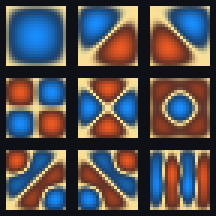

In [9]:
// Helper to turn a 2D mode array [-1..1] into a padded RGB tile with golden Chladni nodal lines
NDArray<Float64> colorizeModeTile(NDArray<Float64> mode2D) {
  return NDArray.scope(() {
    final maxVal = max(abs(mode2D)).scalar;
    final u = mode2D * (1.0 / (maxVal > 1e-12 ? maxVal : 1.0));

    // nodal is ~1.0 along the zero-crossings (u == 0), 0.0 elsewhere
    final nodal = exp((u * u) * -35.0);
    final pos = (u + abs(u)) * 0.5; // positive lobes (warm coral)
    final neg = (abs(u) - u) * 0.5; // negative lobes (ocean blue)

    // Add a 2-pixel dark border around the tile using pad()
    final red = pad(
      pos * 0.82 + nodal * 0.88 + 0.10,
      PadWidth.all(2),
      constantValues: PadValues<Float64>.all(0.06),
    );
    final green = pad(
      pos * 0.25 + neg * 0.45 + nodal * 0.78 + 0.10,
      PadWidth.all(2),
      constantValues: PadValues<Float64>.all(0.06),
    );
    final blue = pad(
      neg * 0.85 + nodal * 0.45 + 0.14,
      PadWidth.all(2),
      constantValues: PadValues<Float64>.all(0.09),
    );

    // Stack the 3 [H, W] channels along axis 2 -> [H, W, 3] RGB image
    return stack([red, green, blue], axis: 2).detachToParentScope();
  });
}

// Assemble a 3x3 grid of the first 9 Square Drum modes using concatenate() and repeat()
final squareGallery = NDArray.scope(() {
  final gridRows = <NDArray<Float64>>[];
  for (var r = 0; r < 3; r++) {
    final rowTiles = <NDArray<Float64>>[];
    for (var c = 0; c < 3; c++) {
      final k = r * 3 + c;
      final mode2D = squareModes.slice([Slice.all(), Index(k)]).reshape([nSquare, nSquare]);
      rowTiles.add(colorizeModeTile(mode2D));
    }
    gridRows.add(concatenate(rowTiles, axis: 1)); // join 3 tiles horizontally
  }
  final fullGrid = concatenate(gridRows, axis: 0); // join 3 rows vertically
  return repeat(repeat(fullGrid, 3, axis: 0), 3, axis: 1).detachToParentScope();
});

display(Markdown('### First 9 Chladni Modes of the Square Drum (Golden Lines = Stationary Sand Contours `u = 0`)'));
Image(squareGallery)

## Step 6: A Menagerie of Drum Shapes with `ogrid` & Boolean Masks

What happens when a drum isn't a square? With `NDArray`, we can carve out **any** 2D shape on our $n \times n$ grid using boolean masks!

### Step 6a: Coordinate Grids & Broadcasting (`ogrid`)

Instead of writing nested `for` loops over $(x, y)$, **`ogrid`** creates two tiny coordinate arrays:
- `yCoord` has shape **`[24, 1]`** (a single vertical column of $y$ values from $-1$ to $+1$).
- `xCoord` has shape **`[1, 24]`** (a single horizontal row of $x$ values from $-1$ to $+1$).

When we combine a `[24, 1]` column and a `[1, 24]` row in an expression like `xCoord * xCoord + yCoord * yCoord`, `NDArray` **broadcasts** them automatically into a full **`[24, 24]`** grid!

Let's use `ogrid`, `<`, `logicalAnd`, and `logicalOr` to carve out **6 classic drum shapes**:
1. **Circular Drum:** $x^2 + y^2 < R^2$ (perfectly symmetric in all directions).
2. **Elliptical Drum:** $(x / a)^2 + (y / b)^2 < 1$ (stretched wider than tall—splits twin modes into different pitches!).
3. **Annular (Ring / Donut) Drum:** $R_{\text{inner}}^2 < x^2 + y^2 < R^2$ (a circular drum with a clamped center post).
4. **L-Shaped Drum:** a square missing its top-right quadrant (features a sharp $270^\circ$ inward corner).
5. **Stadium (Capsule) Drum:** a central rectangle capped by two semicircles (famous in *wave chaos*).
6. **Peanut (Coupled Twin-Bell) Drum:** two overlapping disks joined by a narrow waist (acts like two coupled oscillators!).

In [10]:
// Create a 24x24 open coordinate grid over [-1, 1] x [-1, 1] using ogrid()
const int nGeom = 24;
const double radius = 0.92;
const double hGeom = 2.0 / (nGeom + 1);

final geomCoords = ogrid([
  GridRange(-1.0 + hGeom, 1.0 - hGeom, numPoints: nGeom),
  GridRange(-1.0 + hGeom, 1.0 - hGeom, numPoints: nGeom),
]);
final NDArray<Float64> yCoord = geomCoords[0]; // column vector: shape [24, 1]
final NDArray<Float64> xCoord = geomCoords[1]; // row vector:    shape [1, 24]

// Broadcasting: [1, 24] and [24, 1] combine into a [24, 24] grid of r^2 = x^2 + y^2
final distSquared = xCoord * xCoord + yCoord * yCoord;

// 1. Circular Drum: x^2 + y^2 < 0.92^2 (wide open symmetric kettle-drum)
final NDArray<Boolean> circleMask = distSquared < (radius * radius);

// 2. Slender Elliptical (Marimba-Bar) Drum: (x / 0.95)^2 + (y / 0.34)^2 < 1.0 (2.8:1 aspect ratio)
final NDArray<Boolean> ellipseMask =
    ((xCoord / 0.95) * (xCoord / 0.95) + (yCoord / 0.34) * (yCoord / 0.34)) < 1.0;

// 3. Annular Ring (Gong / Chime Rim) Drum: 0.54^2 < x^2 + y^2 < 0.92^2 (large clamped center post!)
final NDArray<Boolean> ringMask =
    logicalAnd(distSquared < (radius * radius), distSquared > (0.54 * 0.54));

// 4. L-Shaped Drum: inside (-R, R)^2 EXCEPT the top-right quadrant (x >= 0 and y >= 0)
final inBox = logicalAnd(abs(xCoord) < radius, abs(yCoord) < radius);
final NDArray<Boolean> lShapeMask =
    logicalAnd(inBox, logicalOr(xCoord < 0.0, yCoord < 0.0));

// 5. Stadium (Capsule) Drum: rectangle |x| <= 0.42, |y| < 0.52 plus left/right semicircular caps
final stadiumRect = logicalAnd(abs(xCoord) <= 0.42, abs(yCoord) < 0.52);
final stadiumLeftCap = ((xCoord + 0.42) * (xCoord + 0.42) + yCoord * yCoord) < (0.52 * 0.52);
final stadiumRightCap = ((xCoord - 0.42) * (xCoord - 0.42) + yCoord * yCoord) < (0.52 * 0.52);
final NDArray<Boolean> stadiumMask =
    logicalOr(stadiumRect, logicalOr(stadiumLeftCap, stadiumRightCap));

// 6. Peanut (Weakly-Coupled Twin-Bell) Drum: two bells at x = +/-0.52 joined by a narrow neck
final leftBell = ((xCoord + 0.52) * (xCoord + 0.52) + yCoord * yCoord) < (0.43 * 0.43);
final rightBell = ((xCoord - 0.52) * (xCoord - 0.52) + yCoord * yCoord) < (0.43 * 0.43);
final narrowNeck = logicalAnd(abs(xCoord) <= 0.30, abs(yCoord) < 0.14);
final NDArray<Boolean> peanutMask = logicalOr(logicalOr(leftBell, rightBell), narrowNeck);

// Display all 6 drum masks in a 2x3 overview grid
final vSep = NDArray.zeros([nGeom, 2], DType.float64);
final topRowMasks = concatenate([
  circleMask.astype(DType.float64),
  vSep,
  ellipseMask.astype(DType.float64),
  vSep,
  ringMask.astype(DType.float64),
], axis: 1);
final botRowMasks = concatenate([
  lShapeMask.astype(DType.float64),
  vSep,
  stadiumMask.astype(DType.float64),
  vSep,
  peanutMask.astype(DType.float64),
], axis: 1);
final hSep = NDArray.zeros([2, topRowMasks.shape[1]], DType.float64);
final allMasksGrid = concatenate([topRowMasks, hSep, botRowMasks], axis: 0);

Heatmap(
  allMasksGrid,
  title: 'Top: Circle, Slender Ellipse, Annular Ring | Bottom: L-Shape, Stadium, Coupled Peanut',
)

[{"mimeType":"text/html","data":"<div class=\"heatmap-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif;\">\n<div style=\"font-weight: bold; margin-bottom: 12px; color: #cdd6f4; font-size: 1.1em;\">Top: Circle, Slender Ellipse, Annular Ring | Bottom: L-Shape, Stadium, Coupled Peanut</div>\n<div style=\"display: grid; grid-template-columns: repeat(76, 5.2631578947368425px); gap: 1px; background: #313244; padding: 1px; border-radius: 4px;\">\n<div title=\"[0, 0] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 1] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 2] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 3] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 4] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 5] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 6] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 7] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 8] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 9] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 10] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 11] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 12] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 13] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 14] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 15] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 16] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 17] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 18] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 19] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 20] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 21] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 22] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>\n<div title=\"[0, 23] = 0.0000\" style=\"width: 5.2631578947368425px; height: 8.0px; background: rgb(51, 25, 255); border-radius: 1px;\"></div>

### Step 6b: Restricting the Matrix to Any Mask (`Mask` Slicing & Boolean Scatter)

On our $24 \times 24$ grid ($576$ total grid points), only the points where a drum's mask is `true` are free to vibrate. The `false` points outside the mask (including the center post of the Ring drum!) are clamped at height $0$.

Notice how clean the `NDArray` workflow is—the **exact same 4 lines of code** solve *any* drum shape:
1. Flatten the 2D `[24, 24]` mask to a 1D `[576]` mask using **`.flatten()`**.
2. Slice both axes of `l2dGeom` with **`Mask(flatMask)`** to keep only the interior points.
3. Call **`eigh(...)`** to get the eigenvalues and eigenvectors.
4. Scatter any 1D eigenvector back onto a $24 \times 24$ grid with **`mode2D[mask] = modeVec`**!

In [11]:
// Assemble the full 576x576 2D Laplacian on the 24x24 grid
final NDArray<Float64> l2dGeom = NDArray.scope(() {
  final invH2 = 1.0 / (hGeom * hGeom);
  final l1d = (diag(NDArray.ones([nGeom], DType.float64) * 2.0) +
          diag(NDArray.ones([nGeom - 1], DType.float64) * -1.0, k: 1) +
          diag(NDArray.ones([nGeom - 1], DType.float64) * -1.0, k: -1)) *
      invH2;
  final eyeN = NDArray.eye(nGeom, DType.float64);
  return (kron(eyeN, l1d) + kron(l1d, eyeN)).detachToParentScope();
});

// Helper that slices l2dGeom to the true cells of `mask` and solves the eigenvalue problem
({NDArray<Float64> eigenvalues, NDArray<Float64> eigenvectors}) solveMaskedDrum(
  NDArray<Boolean> mask,
) {
  final flat = mask.flatten();
  final subMatrix = l2dGeom.slice([
    Mask(flat),
    Mask(flat),
  ]);
  return eigh(subMatrix);
}

// Solve all 6 drum shapes!
final circleEig  = solveMaskedDrum(circleMask);
final ellipseEig = solveMaskedDrum(ellipseMask);
final ringEig    = solveMaskedDrum(ringMask);
final lShapeEig  = solveMaskedDrum(lShapeMask);
final stadiumEig = solveMaskedDrum(stadiumMask);
final peanutEig  = solveMaskedDrum(peanutMask);

final NDArray<Float64> circleLambdas  = circleEig.eigenvalues;
final NDArray<Float64> circleModes    = circleEig.eigenvectors;
final NDArray<Float64> ellipseLambdas = ellipseEig.eigenvalues;
final NDArray<Float64> ellipseModes   = ellipseEig.eigenvectors;
final NDArray<Float64> ringLambdas    = ringEig.eigenvalues;
final NDArray<Float64> ringModes      = ringEig.eigenvectors;
final NDArray<Float64> lShapeLambdas  = lShapeEig.eigenvalues;
final NDArray<Float64> lShapeModes    = lShapeEig.eigenvectors;
final NDArray<Float64> stadiumLambdas = stadiumEig.eigenvalues;
final NDArray<Float64> stadiumModes   = stadiumEig.eigenvectors;
final NDArray<Float64> peanutLambdas  = peanutEig.eigenvalues;
final NDArray<Float64> peanutModes    = peanutEig.eigenvectors;

print('Interior DOFs -> Circle: ${circleLambdas.shape[0]}, Ellipse: ${ellipseLambdas.shape[0]}, Ring: ${ringLambdas.shape[0]}, L-Shape: ${lShapeLambdas.shape[0]}, Stadium: ${stadiumLambdas.shape[0]}, Peanut: ${peanutLambdas.shape[0]}');

// Demo: scatter Mode 2 of the Peanut Drum back into a 24x24 grid in one line!
final peanutMode2 = NDArray.zeros([nGeom, nGeom], DType.float64);
peanutMode2[peanutMask] = peanutModes.slice([Slice.all(), Index(1)]);
Heatmap(peanutMode2, title: 'Boolean Scatter Demo: Peanut Drum Mode 2 (+ Left Bell, - Right Bell)')

Interior DOFs -> Circle: 408, Ellipse: 160, Ring: 260, L-Shape: 363, Stadium: 260, Peanut: 188

[{"mimeType":"text/plain","data":"Interior DOFs -> Circle: 408, Ellipse: 160, Ring: 260, L-Shape: 363, Stadium: 260, Peanut: 188"},{"mimeType":"text/html","data":"<div class=\"heatmap-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif;\">\n<div style=\"font-weight: bold; margin-bottom: 12px; color: #cdd6f4; font-size: 1.1em;\">Boolean Scatter Demo: Peanut Drum Mode 2 (+ Left Bell, - Right Bell)</div>\n<div style=\"display: grid; grid-template-columns: repeat(24, 16.666666666666668px); gap: 1px; background: #313244; padding: 1px; border-radius: 4px;\">\n<div title=\"[0, 0] = 0.0000\" style=\"width: 16.666666666666668px; height: 16.666666666666668px; background: rgb(152, 254, 191); border-radius: 1px;\"></div>\n<div title=\"[0, 1] = 0.0000\" style=\"width: 16.666666666666668px; height: 16.666666666666668px; background: rgb(152, 254, 191); border-radius: 1px;\"></div>\n<div title=\"[0, 2] = 0.0000\" style=\"width: 16.666666666666668px; height: 16.666666666666668px; background: rgb(152, 254, 191); border-radius: 1px;\"></div>\n<div title=\"[0, 3] = 0.0000\" style=\"width: 16.666666666666668px; height: 16.666666666666668px; background: rgb(152, 254, 191); border-radius: 1px;\"></div>\n<div title=\"[0, 4] = 0.0000\" style=\"width: 16.666666666666668px; height: 16.666666666666668px; background: rgb(152, 254, 191); border-radius: 1px;\"></div>\n<div title=\"[0, 5] = 0.0000\" style=\"width: 16.666666666666668px; height: 16.666666666666668px; background: rgb(152, 254, 191); border-radius: 1px;\"></div>\n<div title=\"[0, 6] = 0.0000\" style=\"width: 16.666666666666668px; height: 16.666666666666668px; background: rgb(152, 254, 191); border-radius: 1px;\"></div>\n<div title=\"[0, 7] = 0.0000\" style=\"width: 16.666666666666668px; height: 16.666666666666668px; background: rgb(152, 254, 191); border-radius: 1px;\"></div>\n<div title=\"[0, 8] = 0.0000\" style=\"width: 16.666666666666668px; height: 16.666666666666668px; background: rgb(152, 254, 191); border-radius: 1px;\"></div>\n<div title=\"[0, 9] = 0.0000\" style=\"width: 16.666666666666668px; height: 16.666666666666668px; background: rgb(152, 254, 191); border-radius: 1px;\"></div>\n<div title=\"[0, 10] = 0.0000\" style=\"width: 16.666666666666668px; height: 16.666666666666668px; background: rgb(152, 254, 191); border-radius: 1px;\"></div>\n<div title=\"[0, 11] = 0.0000\" style=\"width: 16.666666666666668px; height: 16.666666666666668px; background: rgb(152, 254, 191); border-radius: 1px;\"></div>\n<div title=\"[0, 12] = 0.0000\" style=\"width: 16.666666666666668px; height: 16.666666666666668px; background: rgb(152, 254, 191); border-radius: 1px;\"></div>\n<div title=\"[0, 13] = 0.0000\" style=\"width: 16.666666666666668px; height: 16.666666666666668px; background: rgb(152, 254, 191); border-radius: 1px;\"></div>\n<div title=\"[0, 14] = 0.0000\" style=\"width: 16.666666666666668px; height: 16.666666666666668px; background: rgb(152, 254, 191); border-radius: 1px;\"></div>\n<div title=\"[0, 15] = 0.0000\" style=\"width: 16.666666666666668px; height: 16.666666666666668px; background: rgb(152, 254, 191); border-radius: 1px;\"></div>\n<div title=\"[0, 16] = 0.0000\" style=\"width: 16.666666666666668px; height: 16.666666666666668px; background: rgb(152, 254, 191); border-radius: 1px;\"></div>\n<div title=\"[0, 17] = 0.0000\" style=\"width: 16.666666666666668px; height: 16.666666666666668px; background: rgb(152, 254, 191); border-radius: 1px;\"></div>\n<div title=\"[0, 18] = 0.0000\" style=\"width: 16.666666666666668px; height: 16.666666666666668px; background: rgb(152, 254, 191); border-radius: 1px;\"></div>\n<div title=\"[0, 19] = 0.0000\" style=\"width: 16.666666666666668px; height: 16.666666666666668px; background: rgb(152, 254, 191); border-radius: 1px;\"></div>\n<div title=\"[0, 20] = 0.0000\" style=\"width: 16.666666666666668px; height: 16.666666666666668px; background: rgb(152, 2

### Step 6c: Gallery of Chladni Standing Waves Across All 6 Drum Shapes

Let's render the first 6 vibration modes of each of our 6 drums! Look closely at what the geometry does to the waves:
- **1. Circular Drum:** Modes 2 & 3 are identical 2-lobe patterns rotated by $90^\circ$, so they vibrate at the **exact same pitch** ($1.59\times$).
- **2. Elliptical Drum:** Stretching the circle breaks rotational symmetry! Mode 2 (vibrating along the wider horizontal axis) has a **lower pitch** ($1.43\times$) than Mode 3 (vibrating across the narrower vertical axis, $1.79\times$).
- **3. Annular (Ring) Drum:** The clamped center post prevents a single central dome, forcing Mode 1 into a donut ring and packing the overtone frequencies tightly together ($1.00, 1.07, 1.07, 1.27, 1.27, 1.53$).
- **4. L-Shaped Drum:** Every mode bends around the sharp $270^\circ$ inner corner.
- **5. Stadium Drum:** Waves bounce back and forth between the flat parallel walls and curved end-caps.
- **6. Peanut (Twin-Bell) Drum:** Look at Mode 1 vs. Mode 2—in Mode 1 both bells move **in phase** (same color), while in Mode 2 they move **out of phase** (coral vs. blue) with a golden nodal line right across the narrow neck!

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIDEuIENpcmN1bGFyIERydW0g4oCUIEZpcnN0IDYgTW9kZXMgKFJhZGlhbCAmIENpcmN1bGFyIEJlc3NlbCBOb2Rlcyk=\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">1. Circular Drum — First 6 Modes (Radial &amp; Circular Bessel Nodes)</h3>\n</div>"},{"mimeType":"text/html","data":"<img src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIDEuIENpcmN1bGFyIERydW0g4oCUIEZpcnN0IDYgTW9kZXMgKFJhZGlhbCAmIENpcmN1bGFyIEJlc3NlbCBOb2Rlcyk=\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">1. Circular Drum — First 6 Modes (Radial &amp; Circular Bessel Nodes)</h3>\n</div>"},{"mimeType":"text/html","data":"<img src=\"
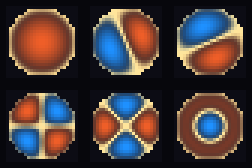

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIDEuIENpcmN1bGFyIERydW0g4oCUIEZpcnN0IDYgTW9kZXMgKFJhZGlhbCAmIENpcmN1bGFyIEJlc3NlbCBOb2Rlcyk=\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">1. Circular Drum — First 6 Modes (Radial &amp; Circular Bessel Nodes)</h3>\n</div>"},{"mimeType":"text/html","data":"<img src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIDEuIENpcmN1bGFyIERydW0g4oCUIEZpcnN0IDYgTW9kZXMgKFJhZGlhbCAmIENpcmN1bGFyIEJlc3NlbCBOb2Rlcyk=\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">1. Circular Drum — First 6 Modes (Radial &amp; Circular Bessel Nodes)</h3>\n</div>"},{"mimeType":"text/html","data":"<img src=\"
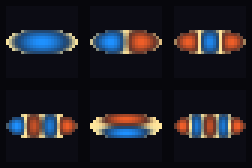

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIDEuIENpcmN1bGFyIERydW0g4oCUIEZpcnN0IDYgTW9kZXMgKFJhZGlhbCAmIENpcmN1bGFyIEJlc3NlbCBOb2Rlcyk=\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">1. Circular Drum — First 6 Modes (Radial &amp; Circular Bessel Nodes)</h3>\n</div>"},{"mimeType":"text/html","data":"<img src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIDEuIENpcmN1bGFyIERydW0g4oCUIEZpcnN0IDYgTW9kZXMgKFJhZGlhbCAmIENpcmN1bGFyIEJlc3NlbCBOb2Rlcyk=\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">1. Circular Drum — First 6 Modes (Radial &amp; Circular Bessel Nodes)</h3>\n</div>"},{"mimeType":"text/html","data":"<img src=\"
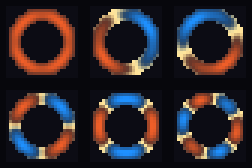

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIDEuIENpcmN1bGFyIERydW0g4oCUIEZpcnN0IDYgTW9kZXMgKFJhZGlhbCAmIENpcmN1bGFyIEJlc3NlbCBOb2Rlcyk=\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">1. Circular Drum — First 6 Modes (Radial &amp; Circular Bessel Nodes)</h3>\n</div>"},{"mimeType":"text/html","data":"<img src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIDEuIENpcmN1bGFyIERydW0g4oCUIEZpcnN0IDYgTW9kZXMgKFJhZGlhbCAmIENpcmN1bGFyIEJlc3NlbCBOb2Rlcyk=\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">1. Circular Drum — First 6 Modes (Radial &amp; Circular Bessel Nodes)</h3>\n</div>"},{"mimeType":"text/html","data":"<img src=\"
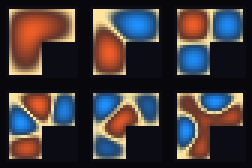

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIDEuIENpcmN1bGFyIERydW0g4oCUIEZpcnN0IDYgTW9kZXMgKFJhZGlhbCAmIENpcmN1bGFyIEJlc3NlbCBOb2Rlcyk=\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">1. Circular Drum — First 6 Modes (Radial &amp; Circular Bessel Nodes)</h3>\n</div>"},{"mimeType":"text/html","data":"<img src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIDEuIENpcmN1bGFyIERydW0g4oCUIEZpcnN0IDYgTW9kZXMgKFJhZGlhbCAmIENpcmN1bGFyIEJlc3NlbCBOb2Rlcyk=\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">1. Circular Drum — First 6 Modes (Radial &amp; Circular Bessel Nodes)</h3>\n</div>"},{"mimeType":"text/html","data":"<img src=\"
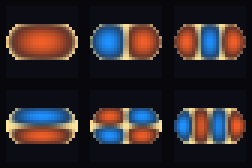

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIDEuIENpcmN1bGFyIERydW0g4oCUIEZpcnN0IDYgTW9kZXMgKFJhZGlhbCAmIENpcmN1bGFyIEJlc3NlbCBOb2Rlcyk=\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">1. Circular Drum — First 6 Modes (Radial &amp; Circular Bessel Nodes)</h3>\n</div>"},{"mimeType":"text/html","data":"<img src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIDEuIENpcmN1bGFyIERydW0g4oCUIEZpcnN0IDYgTW9kZXMgKFJhZGlhbCAmIENpcmN1bGFyIEJlc3NlbCBOb2Rlcyk=\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">1. Circular Drum — First 6 Modes (Radial &amp; Circular Bessel Nodes)</h3>\n</div>"},{"mimeType":"text/html","data":"<img src=\"
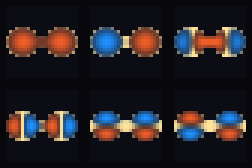

#,Mode k,Circle,Ellipse,Ring (Donut),L-Shape,Stadium,Peanut
0,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,2.0000,1.5898,1.2249,1.0166,1.2705,1.3103,1.0185
2,3.0000,1.5898,1.4942,1.0166,1.4573,1.6959,1.4749
3,4.0000,2.1192,1.7608,1.0545,1.7882,1.8065,1.5704
4,5.0000,2.1304,1.8506,1.0796,1.8348,2.0212,1.6424
5,6.0000,2.2812,2.0257,1.1444,2.0745,2.1033,1.6429


In [12]:
// Render a 2x3 gallery of the first 6 modes for any masked drum shape
NDArray<Float64> renderMaskedDrumGallery(
  NDArray<Float64> eigVecs,
  NDArray<Boolean> mask,
) {
  return NDArray.scope(() {
    final maskF = mask.astype(DType.float64);
    final outsideF = (maskF * -1.0) + 1.0;
    final rows = <NDArray<Float64>>[];

    for (var r = 0; r < 2; r++) {
      final rowTiles = <NDArray<Float64>>[];
      for (var c = 0; c < 3; c++) {
        final k = r * 3 + c;
        final mode2D = NDArray.zeros([nGeom, nGeom], DType.float64);
        mode2D[mask] = eigVecs.slice([Slice.all(), Index(k)]);

        final maxVal = max(abs(mode2D)).scalar;
        final u = mode2D * (1.0 / (maxVal > 1e-12 ? maxVal : 1.0));
        final nodal = exp((u * u) * -35.0) * maskF;
        final pos = (u + abs(u)) * 0.5;
        final neg = (abs(u) - u) * 0.5;

        final red = pad(
          (pos * 0.82 + nodal * 0.88 + 0.12) * maskF + outsideF * 0.05,
          PadWidth.all(2),
          constantValues: PadValues<Float64>.all(0.03),
        );
        final green = pad(
          (pos * 0.25 + neg * 0.45 + nodal * 0.78 + 0.12) * maskF + outsideF * 0.05,
          PadWidth.all(2),
          constantValues: PadValues<Float64>.all(0.03),
        );
        final blue = pad(
          (neg * 0.85 + nodal * 0.45 + 0.16) * maskF + outsideF * 0.08,
          PadWidth.all(2),
          constantValues: PadValues<Float64>.all(0.05),
        );
        rowTiles.add(stack([red, green, blue], axis: 2));
      }
      rows.add(concatenate(rowTiles, axis: 1));
    }
    final grid = concatenate(rows, axis: 0);
    return repeat(repeat(grid, 3, axis: 0), 3, axis: 1).detachToParentScope();
  });
}

display(Markdown('### 1. Circular Drum — First 6 Modes (Radial & Circular Bessel Nodes)'));
display(Image(renderMaskedDrumGallery(circleModes, circleMask)));

display(Markdown('### 2. Elliptical Drum — First 6 Modes (Notice How Twin Modes Split Along Long vs. Short Axes!)'));
display(Image(renderMaskedDrumGallery(ellipseModes, ellipseMask)));

display(Markdown('### 3. Annular (Ring / Donut) Drum — First 6 Modes (Clamped Center Post Forces Waves Around the Ring)'));
display(Image(renderMaskedDrumGallery(ringModes, ringMask)));

display(Markdown('### 4. L-Shaped Drum — First 6 Modes (Waves Bending Around the 270° Re-Entrant Corner)'));
display(Image(renderMaskedDrumGallery(lShapeModes, lShapeMask)));

display(Markdown('### 5. Stadium (Bunimovich) Drum — First 6 Modes (Flat Sides + Semicircular Caps)'));
display(Image(renderMaskedDrumGallery(stadiumModes, stadiumMask)));

display(Markdown('### 6. Peanut (Coupled Twin-Bell) Drum — First 6 Modes (Mode 1 = In-Phase Bells, Mode 2 = Out-of-Phase Bells)'));
display(Image(renderMaskedDrumGallery(peanutModes, peanutMask)));

// Build a comparison table of overtone frequency ratios f_k / f_1 across all 6 drum shapes!
final freqRows = <double>[];
final allLambdaLists = [
  circleLambdas,
  ellipseLambdas,
  ringLambdas,
  lShapeLambdas,
  stadiumLambdas,
  peanutLambdas,
];
for (var k = 0; k < 6; k++) {
  freqRows.add((k + 1).toDouble());
  for (final lambdas in allLambdaLists) {
    freqRows.add(math.sqrt(lambdas.getCell([k]) / lambdas.getCell([0])));
  }
}
Table(
  NDArray.fromList(freqRows, [6, 7], DType.float64),
  headers: ['Mode k', 'Circle', 'Ellipse', 'Ring (Donut)', 'L-Shape', 'Stadium', 'Peanut'],
  title: 'Overtone Frequency Ratios (f_k / f_1) Across All 6 Drum Shapes',
)

## Step 7: Can You Hear the Area of All 7 Drums? (Weyl's Law with `mean`)

A larger drum has a deeper pitch (smaller eigenvalues $\lambda_k$), and a smaller drum has a higher pitch (larger eigenvalues $\lambda_k$).

In 1911, mathematician **Hermann Weyl** discovered something remarkable: if you multiply any drum's eigenvalues $\lambda_k$ by its **area**, the growth rate with mode number $k$ is **universal**—even if the drum is an ellipse, an L-shape, a peanut, or has a hole in the middle like our Ring drum:

$$\lambda_k \times \text{Area} \approx 4\pi k \qquad \Longleftrightarrow \qquad \text{Area} \approx \frac{4\pi k}{\lambda_k}$$

Let's test Weyl's formula across **all 7 drums** (our Square drum from Step 5 plus all 6 masked drums from Step 6) by averaging $\frac{4\pi k}{\lambda_k}$ with **`mean`**:

In [13]:
// Compare true area vs. Weyl's spectral area estimate Area ~ mean(4 * pi * k / lambda_k) across all 7 drums
const int nWeyl = 35;
final kAll = linspace(1.0, nWeyl.toDouble(), nWeyl, dtype: DType.float64);
final kTail = kAll.slice([Slice(start: 14, stop: nWeyl)]);

double estimateAreaFromSpectrum(NDArray<Float64> lambdas) {
  return mean((kTail * (4 * math.pi)) / lambdas.slice([Slice(start: 14, stop: nWeyl)])).scalar;
}

final drumAreaData = <(int id, double trueArea, NDArray<Float64> lambdas)>[
  (1, 1.0, squareLambdas),
  (2, circleLambdas.shape[0] * hGeom * hGeom, circleLambdas),
  (3, ellipseLambdas.shape[0] * hGeom * hGeom, ellipseLambdas),
  (4, ringLambdas.shape[0] * hGeom * hGeom, ringLambdas),
  (5, lShapeLambdas.shape[0] * hGeom * hGeom, lShapeLambdas),
  (6, stadiumLambdas.shape[0] * hGeom * hGeom, stadiumLambdas),
  (7, peanutLambdas.shape[0] * hGeom * hGeom, peanutLambdas),
];

final weylRows = <double>[];
for (final (id, trueArea, lambdas) in drumAreaData) {
  final estArea = estimateAreaFromSpectrum(lambdas);
  weylRows.addAll([id.toDouble(), trueArea, estArea]);
}

display(Table(
  NDArray.fromList(weylRows, [7, 3], DType.float64),
  headers: [
    'Drum (1=Sq, 2=Circ, 3=Ellip, 4=Ring, 5=L, 6=Stad, 7=Peanut)',
    'True Area',
    'Heard Area (4πk / λ_k)',
  ],
  title: "Weyl's Law Across All 7 Drum Shapes: Hearing the Area of Any Drum",
));

// Plot Area * lambda_k for the Ring (Donut) and Peanut drums: both follow the universal slope 4*pi*k!
final trueAreaRing   = ringLambdas.shape[0] * hGeom * hGeom;
final trueAreaPeanut = peanutLambdas.shape[0] * hGeom * hGeom;
display(Plot(
  x: kAll,
  y: ringLambdas.slice([Slice(stop: nWeyl)]) * trueAreaRing,
  title: 'Annular Ring Drum: λ_k × Area vs. Mode k (Slope ≈ 4π ≈ 12.57)',
  color: '#a6e3a1',
));
Plot(
  x: kAll,
  y: peanutLambdas.slice([Slice(stop: nWeyl)]) * trueAreaPeanut,
  title: 'Peanut Twin-Bell Drum: λ_k × Area vs. Mode k (Same Universal Slope ≈ 4π!)',
  color: '#f9e2af',
)

#,"Drum (1=Sq, 2=Circ, 3=Ellip, 4=Ring, 5=L, 6=Stad, 7=Peanut)",True Area,Heard Area (4πk / λ_k)
0,1.0000,1.0000,0.8620
1,2.0000,2.6112,2.4789
2,3.0000,1.0240,1.0875
3,4.0000,1.6640,1.4911
4,5.0000,2.3232,2.1946
5,6.0000,1.6640,1.6462
6,7.0000,1.2032,1.2220


[{"mimeType":"text/html","data":"<div class=\"table-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif; max-height: 400px; overflow: auto;\">\n<div style=\"font-weight: bold; margin-bottom: 12px; color: #cdd6f4; font-size: 1.1em;\">Weyl's Law Across All 7 Drum Shapes: Hearing the Area of Any Drum</div>\n<table style=\"border-collapse: collapse; width: 100%; color: #cdd6f4; font-size: 13px;\">\n<tr style=\"background: #313244; border-bottom: 2px solid #45475a;\">\n<th style=\"padding: 8px 12px; text-align: right; color: #a6adc8;\">#</th>\n<th style=\"padding: 8px 12px; text-align: right; font-weight: bold;\">Drum (1=Sq, 2=Circ, 3=Ellip, 4=Ring, 5=L, 6=Stad, 7=Peanut)</th>\n<th style=\"padding: 8px 12px; text-align: right; font-weight: bold;\">True Area</th>\n<th style=\"padding: 8px 12px; text-align: right; font-weight: bold;\">Heard Area (4πk / λ_k)</th>\n</tr>\n<tr style=\"background: #181825; border-bottom: 1px solid #313244;\">\n<td style=\"padding: 6px 12px; text-align: right; color: #6c7086; font-family: monospace;\">0</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">1.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">1.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.8620</td>\n</tr>\n<tr style=\"background: #1e1e2e; border-bottom: 1px solid #313244;\">\n<td style=\"padding: 6px 12px; text-align: right; color: #6c7086; font-family: monospace;\">1</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">2.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">2.6112</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">2.4789</td>\n</tr>\n<tr style=\"background: #181825; border-bottom: 1px solid #313244;\">\n<td style=\"padding: 6px 12px; text-align: right; color: #6c7086; font-family: monospace;\">2</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">3.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">1.0240</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">1.0875</td>\n</tr>\n<tr style=\"background: #1e1e2e; border-bottom: 1px solid #313244;\">\n<td style=\"padding: 6px 12px; text-align: right; color: #6c7086; font-family: monospace;\">3</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">4.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">1.6640</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">1.4911</td>\n</tr>\n<tr style=\"background: #181825; border-bottom: 1px solid #313244;\">\n<td style=\"padding: 6px 12px; text-align: right; color: #6c7086; font-family: monospace;\">4</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">5.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">2.3232</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">2.1946</td>\n</tr>\n<tr style=\"background: #1e1e2e; border-bottom: 1px solid #313244;\">\n<td style=\"padding: 6px 12px; text-align: right; color: #6c7086; font-family: monospace;\">5</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">6.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">1.6640</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">1.6462</td>\n</tr>\n<tr style=\"background: #181825; border-bottom: 1px solid #313244;\">\n<td style=\"padding: 6px 12px; text-align: right; color: #6c7086; font-family: monospace;\">6</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">7.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">1.2032</t

[{"mimeType":"text/html","data":"<div class=\"table-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif; max-height: 400px; overflow: auto;\">\n<div style=\"font-weight: bold; margin-bottom: 12px; color: #cdd6f4; font-size: 1.1em;\">Weyl's Law Across All 7 Drum Shapes: Hearing the Area of Any Drum</div>\n<table style=\"border-collapse: collapse; width: 100%; color: #cdd6f4; font-size: 13px;\">\n<tr style=\"background: #313244; border-bottom: 2px solid #45475a;\">\n<th style=\"padding: 8px 12px; text-align: right; color: #a6adc8;\">#</th>\n<th style=\"padding: 8px 12px; text-align: right; font-weight: bold;\">Drum (1=Sq, 2=Circ, 3=Ellip, 4=Ring, 5=L, 6=Stad, 7=Peanut)</th>\n<th style=\"padding: 8px 12px; text-align: right; font-weight: bold;\">True Area</th>\n<th style=\"padding: 8px 12px; text-align: right; font-weight: bold;\">Heard Area (4πk / λ_k)</th>\n</tr>\n<tr style=\"background: #181825; border-bottom: 1px solid #313244;\">\n<td style=\"padding: 6px 12px; text-align: right; color: #6c7086; font-family: monospace;\">0</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">1.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">1.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">0.8620</td>\n</tr>\n<tr style=\"background: #1e1e2e; border-bottom: 1px solid #313244;\">\n<td style=\"padding: 6px 12px; text-align: right; color: #6c7086; font-family: monospace;\">1</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">2.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">2.6112</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">2.4789</td>\n</tr>\n<tr style=\"background: #181825; border-bottom: 1px solid #313244;\">\n<td style=\"padding: 6px 12px; text-align: right; color: #6c7086; font-family: monospace;\">2</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">3.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">1.0240</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">1.0875</td>\n</tr>\n<tr style=\"background: #1e1e2e; border-bottom: 1px solid #313244;\">\n<td style=\"padding: 6px 12px; text-align: right; color: #6c7086; font-family: monospace;\">3</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">4.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">1.6640</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">1.4911</td>\n</tr>\n<tr style=\"background: #181825; border-bottom: 1px solid #313244;\">\n<td style=\"padding: 6px 12px; text-align: right; color: #6c7086; font-family: monospace;\">4</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">5.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">2.3232</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">2.1946</td>\n</tr>\n<tr style=\"background: #1e1e2e; border-bottom: 1px solid #313244;\">\n<td style=\"padding: 6px 12px; text-align: right; color: #6c7086; font-family: monospace;\">5</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">6.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">1.6640</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">1.6462</td>\n</tr>\n<tr style=\"background: #181825; border-bottom: 1px solid #313244;\">\n<td style=\"padding: 6px 12px; text-align: right; color: #6c7086; font-family: monospace;\">6</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">7.0000</td>\n<td style=\"padding: 6px 12px; text-align: right; font-family: monospace;\">1.2032</t

## Step 8: Watching a Drum Strike in Slow Motion (`Slice`, `NDArray.scope`, and `Animation`)

In Step 2, we saw how shifted **`Slice`** views let us compare every point with its left and right neighbors without loops.
On a 2D grid `u`, we can take **four** shifted `Slice` views—`north`, `south`, `west`, and `east`—to compute the 2D restoring pull at every pixel in $O(1)$ view creation time:

```dart
final laplacian = (north + south + west + east) - (center * 4.0);
```

By updating the drum height `uCurr` step by step in time and clamping the points outside the L-shape to `0.0` with **`setByMaskScalar(boundaryMask, 0.0)`**, we can watch a mallet strike ripple across the L-shaped drum and diffract around its inner corner!

> **Memory Tip (`NDArray.scope`):** Because `NDArray` stores arrays in native C memory, wrapping our loop step inside **`NDArray.scope(() { ... })`** automatically frees all temporary arrays created inside the block as soon as the step finishes.

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIPCfjqwgSW50ZXJhY3RpdmUgV2F2ZSBTaW11bGF0aW9uOiBXYXRjaCB0aGUgTWFsbGV0IFJpcHBsZSBEaWZmcmFjdCBBcm91bmQgdGhlIEwtQ29ybmVy\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">🎬 Interactive Wave Simulation: Watch the Mallet Ripple Diffract Around the L-Corner</h3>\n</div>"},{"mimeType":"text/html","data":"<div id=\"anim_1791191981407977\" class=\"animation-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif;\">\n  <img id=\"anim_1791191981407977_img\" src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIPCfjqwgSW50ZXJhY3RpdmUgV2F2ZSBTaW11bGF0aW9uOiBXYXRjaCB0aGUgTWFsbGV0IFJpcHBsZSBEaWZmcmFjdCBBcm91bmQgdGhlIEwtQ29ybmVy\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">🎬 Interactive Wave Simulation: Watch the Mallet Ripple Diffract Around the L-Corner</h3>\n</div>"},{"mimeType":"text/html","data":"<div id=\"anim_1791191981407977\" class=\"animation-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif;\">\n  <img id=\"anim_1791191981407977_img\" src=\"
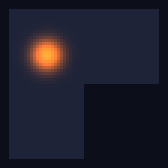
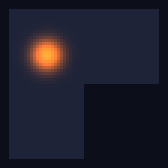
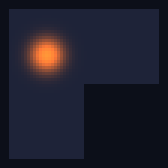
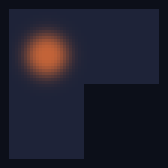
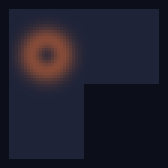
...
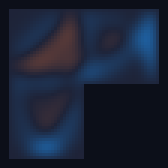
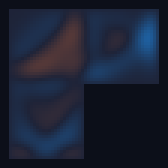
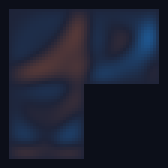
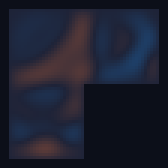
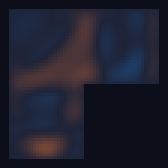

In [14]:
// Simulate a mallet strike on a 56x56 L-Shaped Drum and render an interactive Animation
final waveAnimation = NDArray.scope(() {
  const nSim = 56;
  final simCoords = ogrid([
    GridRange(-1.0, 1.0, numPoints: nSim),
    GridRange(-1.0, 1.0, numPoints: nSim),
  ]);
  final yS = simCoords[0];
  final xS = simCoords[1];

  // L-shaped drum interior mask and exterior boundary mask
  final inSimBox = logicalAnd(abs(xS) < 0.92, abs(yS) < 0.92);
  final interiorMask = logicalAnd(inSimBox, logicalOr(xS < 0.0, yS < 0.0));
  final boundaryMask = logicalNot(interiorMask);
  final interiorF = interiorMask.astype(DType.float64);
  final exteriorF = boundaryMask.astype(DType.float64);

  // Initial strike: a smooth Gaussian bump in the lower-left wing (-0.45, -0.35)
  final dist2 = ((xS + 0.45) * (xS + 0.45)) + ((yS + 0.35) * (yS + 0.35));
  var uPrev = exp(dist2 * -35.0) * interiorF;
  var uCurr = uPrev.copy();

  final frames = <NDArray<Float64>>[];
  for (var step = 0; step < 108; step++) {
    if (step % 3 == 0) {
      frames.add(NDArray.scope(() {
        final uNorm = uCurr * 1.6;
        final pos = (uNorm + abs(uNorm)) * 0.5;
        final neg = (abs(uNorm) - uNorm) * 0.5;
        final rCh = (pos * 0.90 + 0.12) * interiorF + exteriorF * 0.05;
        final gCh = (pos * 0.35 + neg * 0.55 + 0.14) * interiorF + exteriorF * 0.06;
        final bCh = (neg * 0.95 + 0.22) * interiorF + exteriorF * 0.10;
        final rgb = stack([rCh, gCh, bCh], axis: 2);
        return repeat(repeat(rgb, 3, axis: 0), 3, axis: 1).detachToParentScope();
      }));
    }

    // Advance one time step using 4 shifted neighbor Slice views
    final uNext = NDArray.scope(() {
      final next = NDArray.zeros([nSim, nSim], DType.float64);
      final center     = uCurr.slice([Slice(start: 1, stop: nSim - 1), Slice(start: 1, stop: nSim - 1)]);
      final prevCenter = uPrev.slice([Slice(start: 1, stop: nSim - 1), Slice(start: 1, stop: nSim - 1)]);
      final north      = uCurr.slice([Slice(start: 0, stop: nSim - 2), Slice(start: 1, stop: nSim - 1)]);
      final south      = uCurr.slice([Slice(start: 2, stop: nSim),     Slice(start: 1, stop: nSim - 1)]);
      final west       = uCurr.slice([Slice(start: 1, stop: nSim - 1), Slice(start: 0, stop: nSim - 2)]);
      final east       = uCurr.slice([Slice(start: 1, stop: nSim - 1), Slice(start: 2, stop: nSim)]);

      final laplacian = (north + south + west + east) - (center * 4.0);
      final nextInterior = next.slice([Slice(start: 1, stop: nSim - 1), Slice(start: 1, stop: nSim - 1)]);
      ((center * 1.996) - (prevCenter * 0.996) + (laplacian * 0.18)).copy(out: nextInterior);

      next.setByMaskScalar(boundaryMask, 0.0); // clamp outside of L-shape to 0
      return next.detachToParentScope();
    });
    uPrev = uCurr;
    uCurr = uNext;
  }

  for (final f in frames) {
    f.detachToParentScope();
  }
  return Animation(frames, fps: 15);
});

display(Markdown('### 🎬 Interactive Wave Simulation: Watch the Mallet Ripple Diffract Around the L-Corner'));
waveAnimation

## Step 9: The 6-Shape Drum Kit — Hearing Both Pitch & Overtone Timbre (`Audio` & `Spectrogram`)

Why can two drums sound different when you strike them? Geometry changes **two** acoustic properties at once:

1. **Natural Pitch (Same Membrane Tension, $f_k \propto \sqrt{\lambda_k}$):**
   If you carve all 6 shapes out of the **same stretched sheet** (without retuning them to the same fundamental!), smaller or narrower shapes have much higher $\lambda_1$:
   - The wide **Circular Drum** is a deep bass timpani ($140\text{ Hz}$).
   - The **L-Shape** ($175\text{ Hz}$) and **Stadium** ($195\text{ Hz}$) are mid-range tom-toms.
   - The **Peanut Twin-Bell** ($245\text{ Hz}$) is a higher bongo that **pulsates ("wah-wah-wah")** as energy sloshes between its two bells.
   - The **Slender Ellipse** ($315\text{ Hz}$) and **Annular Ring** ($375\text{ Hz}$) ring over an octave higher because waves are squeezed across their narrow width!

2. **Overtone Chord / Timbre (Retuned to the Same Fundamental $f_1 = 220\text{ Hz}$):**
   Even if we tighten/loosen each drum so all 6 start at the **exact same lowest note** ($f_1 = 220\text{ Hz}$), projecting an off-center mallet strike onto each drum's **eigenvectors** (`matmul(malletVec, eigenvectors)`) excites a completely different chord of overtones ($f_k / f_1$):
   - **Peanut Twin-Bell:** Striking the left bell excites Mode 1 ($\uparrow\uparrow$, $220\text{ Hz}$) and Mode 2 ($\uparrow\downarrow$, $\approx 228\text{ Hz}$) equally, creating a dramatic **$8\text{ Hz}$ "wah-wah-wah-wah" beating**!
   - **Annular Ring (Gong Rim):** 7 modes packed tightly between $220\text{ Hz}$ and $300\text{ Hz}$ interfere to produce a **shimmering metallic church-bell / gong** tone!
   - **Slender Ellipse:** Closely spaced horizontal bar modes ($1.00, 1.15, 1.35, 1.59\times$) create a bright, hollow **marimba-bar** timbre!

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIPCfjqcgVG91ciAxIChDbGljayBQbGF5ISk6IEFsbCA2IERydW1zIENhcnZlZCBmcm9tIHRoZSAqU2FtZSBNZW1icmFuZSogKFRydWUgUGh5c2ljYWwgUGl0Y2ggKyBUaW1icmUpCioqT3JkZXI6KiogYDEuIENpcmNsZSAoRGVlcCBCYXNzKWAg4oaSIGAyLiBMLVNoYXBlYCDihpIgYDMuIFN0YWRpdW1gIOKGkiBgNC4gUGVhbnV0IChQdWxzaW5nIEJvbmdvKWAg4oaSIGA1LiBTbGVuZGVyIEVsbGlwc2UgKEhpZ2ggQmFyKWAg4oaSIGA2LiBBbm51bGFyIFJpbmcgKEhpZ2ggTWV0YWxsaWMgQ2hpbWUpYA==\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">🎧 Tour 1 (Click Play!): All 6 Drums Carved from the <em>Same Membrane</em> (True Physical Pitch + Timbre)</h3>\n<p style=\"margin: 4px 0; color: #cdd6f4;\"><strong>Order:</strong> <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">1. Circle (Deep Bass)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">2. L-Shape</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">3. Stadium</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">4. Peanut (Pulsing Bongo)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">5. Slender Ellipse (High Bar)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">6. Annular Ring (High Metallic Chime)</code></p>\n</div>"},{"mimeType":"text/html","data":"<audio controls style=\"width: 100%; max-width: 500px;\" src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIPCfjqcgVG91ciAxIChDbGljayBQbGF5ISk6IEFsbCA2IERydW1zIENhcnZlZCBmcm9tIHRoZSAqU2FtZSBNZW1icmFuZSogKFRydWUgUGh5c2ljYWwgUGl0Y2ggKyBUaW1icmUpCioqT3JkZXI6KiogYDEuIENpcmNsZSAoRGVlcCBCYXNzKWAg4oaSIGAyLiBMLVNoYXBlYCDihpIgYDMuIFN0YWRpdW1gIOKGkiBgNC4gUGVhbnV0IChQdWxzaW5nIEJvbmdvKWAg4oaSIGA1LiBTbGVuZGVyIEVsbGlwc2UgKEhpZ2ggQmFyKWAg4oaSIGA2LiBBbm51bGFyIFJpbmcgKEhpZ2ggTWV0YWxsaWMgQ2hpbWUpYA==\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">🎧 Tour 1 (Click Play!): All 6 Drums Carved from the <em>Same Membrane</em> (True Physical Pitch + Timbre)</h3>\n<p style=\"margin: 4px 0; color: #cdd6f4;\"><strong>Order:</strong> <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">1. Circle (Deep Bass)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">2. L-Shape</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">3. Stadium</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">4. Peanut (Pulsing Bongo)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">5. Slender Ellipse (High Bar)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">6. Annular Ring (High Metallic Chime)</code></p>\n</div>"},{"mimeType":"text/html","data":"<audio controls style=\"width: 100%; max-width: 500px;\" src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIPCfjqcgVG91ciAxIChDbGljayBQbGF5ISk6IEFsbCA2IERydW1zIENhcnZlZCBmcm9tIHRoZSAqU2FtZSBNZW1icmFuZSogKFRydWUgUGh5c2ljYWwgUGl0Y2ggKyBUaW1icmUpCioqT3JkZXI6KiogYDEuIENpcmNsZSAoRGVlcCBCYXNzKWAg4oaSIGAyLiBMLVNoYXBlYCDihpIgYDMuIFN0YWRpdW1gIOKGkiBgNC4gUGVhbnV0IChQdWxzaW5nIEJvbmdvKWAg4oaSIGA1LiBTbGVuZGVyIEVsbGlwc2UgKEhpZ2ggQmFyKWAg4oaSIGA2LiBBbm51bGFyIFJpbmcgKEhpZ2ggTWV0YWxsaWMgQ2hpbWUpYA==\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">🎧 Tour 1 (Click Play!): All 6 Drums Carved from the <em>Same Membrane</em> (True Physical Pitch + Timbre)</h3>\n<p style=\"margin: 4px 0; color: #cdd6f4;\"><strong>Order:</strong> <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">1. Circle (Deep Bass)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">2. L-Shape</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">3. Stadium</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">4. Peanut (Pulsing Bongo)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">5. Slender Ellipse (High Bar)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">6. Annular Ring (High Metallic Chime)</code></p>\n</div>"},{"mimeType":"text/html","data":"<audio controls style=\"width: 100%; max-width: 500px;\" src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIPCfjqcgVG91ciAxIChDbGljayBQbGF5ISk6IEFsbCA2IERydW1zIENhcnZlZCBmcm9tIHRoZSAqU2FtZSBNZW1icmFuZSogKFRydWUgUGh5c2ljYWwgUGl0Y2ggKyBUaW1icmUpCioqT3JkZXI6KiogYDEuIENpcmNsZSAoRGVlcCBCYXNzKWAg4oaSIGAyLiBMLVNoYXBlYCDihpIgYDMuIFN0YWRpdW1gIOKGkiBgNC4gUGVhbnV0IChQdWxzaW5nIEJvbmdvKWAg4oaSIGA1LiBTbGVuZGVyIEVsbGlwc2UgKEhpZ2ggQmFyKWAg4oaSIGA2LiBBbm51bGFyIFJpbmcgKEhpZ2ggTWV0YWxsaWMgQ2hpbWUpYA==\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">🎧 Tour 1 (Click Play!): All 6 Drums Carved from the <em>Same Membrane</em> (True Physical Pitch + Timbre)</h3>\n<p style=\"margin: 4px 0; color: #cdd6f4;\"><strong>Order:</strong> <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">1. Circle (Deep Bass)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">2. L-Shape</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">3. Stadium</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">4. Peanut (Pulsing Bongo)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">5. Slender Ellipse (High Bar)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">6. Annular Ring (High Metallic Chime)</code></p>\n</div>"},{"mimeType":"text/html","data":"<audio controls style=\"width: 100%; max-width: 500px;\" src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIPCfjqcgVG91ciAxIChDbGljayBQbGF5ISk6IEFsbCA2IERydW1zIENhcnZlZCBmcm9tIHRoZSAqU2FtZSBNZW1icmFuZSogKFRydWUgUGh5c2ljYWwgUGl0Y2ggKyBUaW1icmUpCioqT3JkZXI6KiogYDEuIENpcmNsZSAoRGVlcCBCYXNzKWAg4oaSIGAyLiBMLVNoYXBlYCDihpIgYDMuIFN0YWRpdW1gIOKGkiBgNC4gUGVhbnV0IChQdWxzaW5nIEJvbmdvKWAg4oaSIGA1LiBTbGVuZGVyIEVsbGlwc2UgKEhpZ2ggQmFyKWAg4oaSIGA2LiBBbm51bGFyIFJpbmcgKEhpZ2ggTWV0YWxsaWMgQ2hpbWUpYA==\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">🎧 Tour 1 (Click Play!): All 6 Drums Carved from the <em>Same Membrane</em> (True Physical Pitch + Timbre)</h3>\n<p style=\"margin: 4px 0; color: #cdd6f4;\"><strong>Order:</strong> <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">1. Circle (Deep Bass)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">2. L-Shape</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">3. Stadium</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">4. Peanut (Pulsing Bongo)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">5. Slender Ellipse (High Bar)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">6. Annular Ring (High Metallic Chime)</code></p>\n</div>"},{"mimeType":"text/html","data":"<audio controls style=\"width: 100%; max-width: 500px;\" src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIPCfjqcgVG91ciAxIChDbGljayBQbGF5ISk6IEFsbCA2IERydW1zIENhcnZlZCBmcm9tIHRoZSAqU2FtZSBNZW1icmFuZSogKFRydWUgUGh5c2ljYWwgUGl0Y2ggKyBUaW1icmUpCioqT3JkZXI6KiogYDEuIENpcmNsZSAoRGVlcCBCYXNzKWAg4oaSIGAyLiBMLVNoYXBlYCDihpIgYDMuIFN0YWRpdW1gIOKGkiBgNC4gUGVhbnV0IChQdWxzaW5nIEJvbmdvKWAg4oaSIGA1LiBTbGVuZGVyIEVsbGlwc2UgKEhpZ2ggQmFyKWAg4oaSIGA2LiBBbm51bGFyIFJpbmcgKEhpZ2ggTWV0YWxsaWMgQ2hpbWUpYA==\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">🎧 Tour 1 (Click Play!): All 6 Drums Carved from the <em>Same Membrane</em> (True Physical Pitch + Timbre)</h3>\n<p style=\"margin: 4px 0; color: #cdd6f4;\"><strong>Order:</strong> <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">1. Circle (Deep Bass)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">2. L-Shape</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">3. Stadium</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">4. Peanut (Pulsing Bongo)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">5. Slender Ellipse (High Bar)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">6. Annular Ring (High Metallic Chime)</code></p>\n</div>"},{"mimeType":"text/html","data":"<audio controls style=\"width: 100%; max-width: 500px;\" src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIPCfjqcgVG91ciAxIChDbGljayBQbGF5ISk6IEFsbCA2IERydW1zIENhcnZlZCBmcm9tIHRoZSAqU2FtZSBNZW1icmFuZSogKFRydWUgUGh5c2ljYWwgUGl0Y2ggKyBUaW1icmUpCioqT3JkZXI6KiogYDEuIENpcmNsZSAoRGVlcCBCYXNzKWAg4oaSIGAyLiBMLVNoYXBlYCDihpIgYDMuIFN0YWRpdW1gIOKGkiBgNC4gUGVhbnV0IChQdWxzaW5nIEJvbmdvKWAg4oaSIGA1LiBTbGVuZGVyIEVsbGlwc2UgKEhpZ2ggQmFyKWAg4oaSIGA2LiBBbm51bGFyIFJpbmcgKEhpZ2ggTWV0YWxsaWMgQ2hpbWUpYA==\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">🎧 Tour 1 (Click Play!): All 6 Drums Carved from the <em>Same Membrane</em> (True Physical Pitch + Timbre)</h3>\n<p style=\"margin: 4px 0; color: #cdd6f4;\"><strong>Order:</strong> <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">1. Circle (Deep Bass)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">2. L-Shape</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">3. Stadium</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">4. Peanut (Pulsing Bongo)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">5. Slender Ellipse (High Bar)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">6. Annular Ring (High Metallic Chime)</code></p>\n</div>"},{"mimeType":"text/html","data":"<audio controls style=\"width: 100%; max-width: 500px;\" src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIPCfjqcgVG91ciAxIChDbGljayBQbGF5ISk6IEFsbCA2IERydW1zIENhcnZlZCBmcm9tIHRoZSAqU2FtZSBNZW1icmFuZSogKFRydWUgUGh5c2ljYWwgUGl0Y2ggKyBUaW1icmUpCioqT3JkZXI6KiogYDEuIENpcmNsZSAoRGVlcCBCYXNzKWAg4oaSIGAyLiBMLVNoYXBlYCDihpIgYDMuIFN0YWRpdW1gIOKGkiBgNC4gUGVhbnV0IChQdWxzaW5nIEJvbmdvKWAg4oaSIGA1LiBTbGVuZGVyIEVsbGlwc2UgKEhpZ2ggQmFyKWAg4oaSIGA2LiBBbm51bGFyIFJpbmcgKEhpZ2ggTWV0YWxsaWMgQ2hpbWUpYA==\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">🎧 Tour 1 (Click Play!): All 6 Drums Carved from the <em>Same Membrane</em> (True Physical Pitch + Timbre)</h3>\n<p style=\"margin: 4px 0; color: #cdd6f4;\"><strong>Order:</strong> <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">1. Circle (Deep Bass)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">2. L-Shape</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">3. Stadium</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">4. Peanut (Pulsing Bongo)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">5. Slender Ellipse (High Bar)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">6. Annular Ring (High Metallic Chime)</code></p>\n</div>"},{"mimeType":"text/html","data":"<audio controls style=\"width: 100%; max-width: 500px;\" src=\"
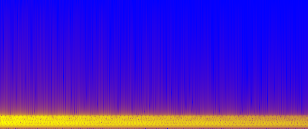

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIPCfjqcgVG91ciAxIChDbGljayBQbGF5ISk6IEFsbCA2IERydW1zIENhcnZlZCBmcm9tIHRoZSAqU2FtZSBNZW1icmFuZSogKFRydWUgUGh5c2ljYWwgUGl0Y2ggKyBUaW1icmUpCioqT3JkZXI6KiogYDEuIENpcmNsZSAoRGVlcCBCYXNzKWAg4oaSIGAyLiBMLVNoYXBlYCDihpIgYDMuIFN0YWRpdW1gIOKGkiBgNC4gUGVhbnV0IChQdWxzaW5nIEJvbmdvKWAg4oaSIGA1LiBTbGVuZGVyIEVsbGlwc2UgKEhpZ2ggQmFyKWAg4oaSIGA2LiBBbm51bGFyIFJpbmcgKEhpZ2ggTWV0YWxsaWMgQ2hpbWUpYA==\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">🎧 Tour 1 (Click Play!): All 6 Drums Carved from the <em>Same Membrane</em> (True Physical Pitch + Timbre)</h3>\n<p style=\"margin: 4px 0; color: #cdd6f4;\"><strong>Order:</strong> <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">1. Circle (Deep Bass)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">2. L-Shape</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">3. Stadium</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">4. Peanut (Pulsing Bongo)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">5. Slender Ellipse (High Bar)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">6. Annular Ring (High Metallic Chime)</code></p>\n</div>"},{"mimeType":"text/html","data":"<audio controls style=\"width: 100%; max-width: 500px;\" src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIPCfjqcgVG91ciAxIChDbGljayBQbGF5ISk6IEFsbCA2IERydW1zIENhcnZlZCBmcm9tIHRoZSAqU2FtZSBNZW1icmFuZSogKFRydWUgUGh5c2ljYWwgUGl0Y2ggKyBUaW1icmUpCioqT3JkZXI6KiogYDEuIENpcmNsZSAoRGVlcCBCYXNzKWAg4oaSIGAyLiBMLVNoYXBlYCDihpIgYDMuIFN0YWRpdW1gIOKGkiBgNC4gUGVhbnV0IChQdWxzaW5nIEJvbmdvKWAg4oaSIGA1LiBTbGVuZGVyIEVsbGlwc2UgKEhpZ2ggQmFyKWAg4oaSIGA2LiBBbm51bGFyIFJpbmcgKEhpZ2ggTWV0YWxsaWMgQ2hpbWUpYA==\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">🎧 Tour 1 (Click Play!): All 6 Drums Carved from the <em>Same Membrane</em> (True Physical Pitch + Timbre)</h3>\n<p style=\"margin: 4px 0; color: #cdd6f4;\"><strong>Order:</strong> <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">1. Circle (Deep Bass)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">2. L-Shape</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">3. Stadium</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">4. Peanut (Pulsing Bongo)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">5. Slender Ellipse (High Bar)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">6. Annular Ring (High Metallic Chime)</code></p>\n</div>"},{"mimeType":"text/html","data":"<audio controls style=\"width: 100%; max-width: 500px;\" src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIPCfjqcgVG91ciAxIChDbGljayBQbGF5ISk6IEFsbCA2IERydW1zIENhcnZlZCBmcm9tIHRoZSAqU2FtZSBNZW1icmFuZSogKFRydWUgUGh5c2ljYWwgUGl0Y2ggKyBUaW1icmUpCioqT3JkZXI6KiogYDEuIENpcmNsZSAoRGVlcCBCYXNzKWAg4oaSIGAyLiBMLVNoYXBlYCDihpIgYDMuIFN0YWRpdW1gIOKGkiBgNC4gUGVhbnV0IChQdWxzaW5nIEJvbmdvKWAg4oaSIGA1LiBTbGVuZGVyIEVsbGlwc2UgKEhpZ2ggQmFyKWAg4oaSIGA2LiBBbm51bGFyIFJpbmcgKEhpZ2ggTWV0YWxsaWMgQ2hpbWUpYA==\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">🎧 Tour 1 (Click Play!): All 6 Drums Carved from the <em>Same Membrane</em> (True Physical Pitch + Timbre)</h3>\n<p style=\"margin: 4px 0; color: #cdd6f4;\"><strong>Order:</strong> <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">1. Circle (Deep Bass)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">2. L-Shape</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">3. Stadium</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">4. Peanut (Pulsing Bongo)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">5. Slender Ellipse (High Bar)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">6. Annular Ring (High Metallic Chime)</code></p>\n</div>"},{"mimeType":"text/html","data":"<audio controls style=\"width: 100%; max-width: 500px;\" src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIPCfjqcgVG91ciAxIChDbGljayBQbGF5ISk6IEFsbCA2IERydW1zIENhcnZlZCBmcm9tIHRoZSAqU2FtZSBNZW1icmFuZSogKFRydWUgUGh5c2ljYWwgUGl0Y2ggKyBUaW1icmUpCioqT3JkZXI6KiogYDEuIENpcmNsZSAoRGVlcCBCYXNzKWAg4oaSIGAyLiBMLVNoYXBlYCDihpIgYDMuIFN0YWRpdW1gIOKGkiBgNC4gUGVhbnV0IChQdWxzaW5nIEJvbmdvKWAg4oaSIGA1LiBTbGVuZGVyIEVsbGlwc2UgKEhpZ2ggQmFyKWAg4oaSIGA2LiBBbm51bGFyIFJpbmcgKEhpZ2ggTWV0YWxsaWMgQ2hpbWUpYA==\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">🎧 Tour 1 (Click Play!): All 6 Drums Carved from the <em>Same Membrane</em> (True Physical Pitch + Timbre)</h3>\n<p style=\"margin: 4px 0; color: #cdd6f4;\"><strong>Order:</strong> <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">1. Circle (Deep Bass)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">2. L-Shape</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">3. Stadium</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">4. Peanut (Pulsing Bongo)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">5. Slender Ellipse (High Bar)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">6. Annular Ring (High Metallic Chime)</code></p>\n</div>"},{"mimeType":"text/html","data":"<audio controls style=\"width: 100%; max-width: 500px;\" src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIPCfjqcgVG91ciAxIChDbGljayBQbGF5ISk6IEFsbCA2IERydW1zIENhcnZlZCBmcm9tIHRoZSAqU2FtZSBNZW1icmFuZSogKFRydWUgUGh5c2ljYWwgUGl0Y2ggKyBUaW1icmUpCioqT3JkZXI6KiogYDEuIENpcmNsZSAoRGVlcCBCYXNzKWAg4oaSIGAyLiBMLVNoYXBlYCDihpIgYDMuIFN0YWRpdW1gIOKGkiBgNC4gUGVhbnV0IChQdWxzaW5nIEJvbmdvKWAg4oaSIGA1LiBTbGVuZGVyIEVsbGlwc2UgKEhpZ2ggQmFyKWAg4oaSIGA2LiBBbm51bGFyIFJpbmcgKEhpZ2ggTWV0YWxsaWMgQ2hpbWUpYA==\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">🎧 Tour 1 (Click Play!): All 6 Drums Carved from the <em>Same Membrane</em> (True Physical Pitch + Timbre)</h3>\n<p style=\"margin: 4px 0; color: #cdd6f4;\"><strong>Order:</strong> <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">1. Circle (Deep Bass)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">2. L-Shape</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">3. Stadium</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">4. Peanut (Pulsing Bongo)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">5. Slender Ellipse (High Bar)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">6. Annular Ring (High Metallic Chime)</code></p>\n</div>"},{"mimeType":"text/html","data":"<audio controls style=\"width: 100%; max-width: 500px;\" src=\"
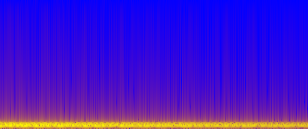

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIPCfjqcgVG91ciAxIChDbGljayBQbGF5ISk6IEFsbCA2IERydW1zIENhcnZlZCBmcm9tIHRoZSAqU2FtZSBNZW1icmFuZSogKFRydWUgUGh5c2ljYWwgUGl0Y2ggKyBUaW1icmUpCioqT3JkZXI6KiogYDEuIENpcmNsZSAoRGVlcCBCYXNzKWAg4oaSIGAyLiBMLVNoYXBlYCDihpIgYDMuIFN0YWRpdW1gIOKGkiBgNC4gUGVhbnV0IChQdWxzaW5nIEJvbmdvKWAg4oaSIGA1LiBTbGVuZGVyIEVsbGlwc2UgKEhpZ2ggQmFyKWAg4oaSIGA2LiBBbm51bGFyIFJpbmcgKEhpZ2ggTWV0YWxsaWMgQ2hpbWUpYA==\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">🎧 Tour 1 (Click Play!): All 6 Drums Carved from the <em>Same Membrane</em> (True Physical Pitch + Timbre)</h3>\n<p style=\"margin: 4px 0; color: #cdd6f4;\"><strong>Order:</strong> <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">1. Circle (Deep Bass)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">2. L-Shape</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">3. Stadium</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">4. Peanut (Pulsing Bongo)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">5. Slender Ellipse (High Bar)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">6. Annular Ring (High Metallic Chime)</code></p>\n</div>"},{"mimeType":"text/html","data":"<audio controls style=\"width: 100%; max-width: 500px;\" src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIPCfjqcgVG91ciAxIChDbGljayBQbGF5ISk6IEFsbCA2IERydW1zIENhcnZlZCBmcm9tIHRoZSAqU2FtZSBNZW1icmFuZSogKFRydWUgUGh5c2ljYWwgUGl0Y2ggKyBUaW1icmUpCioqT3JkZXI6KiogYDEuIENpcmNsZSAoRGVlcCBCYXNzKWAg4oaSIGAyLiBMLVNoYXBlYCDihpIgYDMuIFN0YWRpdW1gIOKGkiBgNC4gUGVhbnV0IChQdWxzaW5nIEJvbmdvKWAg4oaSIGA1LiBTbGVuZGVyIEVsbGlwc2UgKEhpZ2ggQmFyKWAg4oaSIGA2LiBBbm51bGFyIFJpbmcgKEhpZ2ggTWV0YWxsaWMgQ2hpbWUpYA==\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">🎧 Tour 1 (Click Play!): All 6 Drums Carved from the <em>Same Membrane</em> (True Physical Pitch + Timbre)</h3>\n<p style=\"margin: 4px 0; color: #cdd6f4;\"><strong>Order:</strong> <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">1. Circle (Deep Bass)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">2. L-Shape</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">3. Stadium</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">4. Peanut (Pulsing Bongo)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">5. Slender Ellipse (High Bar)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">6. Annular Ring (High Metallic Chime)</code></p>\n</div>"},{"mimeType":"text/html","data":"<audio controls style=\"width: 100%; max-width: 500px;\" src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIPCfjqcgVG91ciAxIChDbGljayBQbGF5ISk6IEFsbCA2IERydW1zIENhcnZlZCBmcm9tIHRoZSAqU2FtZSBNZW1icmFuZSogKFRydWUgUGh5c2ljYWwgUGl0Y2ggKyBUaW1icmUpCioqT3JkZXI6KiogYDEuIENpcmNsZSAoRGVlcCBCYXNzKWAg4oaSIGAyLiBMLVNoYXBlYCDihpIgYDMuIFN0YWRpdW1gIOKGkiBgNC4gUGVhbnV0IChQdWxzaW5nIEJvbmdvKWAg4oaSIGA1LiBTbGVuZGVyIEVsbGlwc2UgKEhpZ2ggQmFyKWAg4oaSIGA2LiBBbm51bGFyIFJpbmcgKEhpZ2ggTWV0YWxsaWMgQ2hpbWUpYA==\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">🎧 Tour 1 (Click Play!): All 6 Drums Carved from the <em>Same Membrane</em> (True Physical Pitch + Timbre)</h3>\n<p style=\"margin: 4px 0; color: #cdd6f4;\"><strong>Order:</strong> <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">1. Circle (Deep Bass)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">2. L-Shape</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">3. Stadium</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">4. Peanut (Pulsing Bongo)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">5. Slender Ellipse (High Bar)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">6. Annular Ring (High Metallic Chime)</code></p>\n</div>"},{"mimeType":"text/html","data":"<audio controls style=\"width: 100%; max-width: 500px;\" src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIPCfjqcgVG91ciAxIChDbGljayBQbGF5ISk6IEFsbCA2IERydW1zIENhcnZlZCBmcm9tIHRoZSAqU2FtZSBNZW1icmFuZSogKFRydWUgUGh5c2ljYWwgUGl0Y2ggKyBUaW1icmUpCioqT3JkZXI6KiogYDEuIENpcmNsZSAoRGVlcCBCYXNzKWAg4oaSIGAyLiBMLVNoYXBlYCDihpIgYDMuIFN0YWRpdW1gIOKGkiBgNC4gUGVhbnV0IChQdWxzaW5nIEJvbmdvKWAg4oaSIGA1LiBTbGVuZGVyIEVsbGlwc2UgKEhpZ2ggQmFyKWAg4oaSIGA2LiBBbm51bGFyIFJpbmcgKEhpZ2ggTWV0YWxsaWMgQ2hpbWUpYA==\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">🎧 Tour 1 (Click Play!): All 6 Drums Carved from the <em>Same Membrane</em> (True Physical Pitch + Timbre)</h3>\n<p style=\"margin: 4px 0; color: #cdd6f4;\"><strong>Order:</strong> <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">1. Circle (Deep Bass)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">2. L-Shape</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">3. Stadium</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">4. Peanut (Pulsing Bongo)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">5. Slender Ellipse (High Bar)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">6. Annular Ring (High Metallic Chime)</code></p>\n</div>"},{"mimeType":"text/html","data":"<audio controls style=\"width: 100%; max-width: 500px;\" src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIPCfjqcgVG91ciAxIChDbGljayBQbGF5ISk6IEFsbCA2IERydW1zIENhcnZlZCBmcm9tIHRoZSAqU2FtZSBNZW1icmFuZSogKFRydWUgUGh5c2ljYWwgUGl0Y2ggKyBUaW1icmUpCioqT3JkZXI6KiogYDEuIENpcmNsZSAoRGVlcCBCYXNzKWAg4oaSIGAyLiBMLVNoYXBlYCDihpIgYDMuIFN0YWRpdW1gIOKGkiBgNC4gUGVhbnV0IChQdWxzaW5nIEJvbmdvKWAg4oaSIGA1LiBTbGVuZGVyIEVsbGlwc2UgKEhpZ2ggQmFyKWAg4oaSIGA2LiBBbm51bGFyIFJpbmcgKEhpZ2ggTWV0YWxsaWMgQ2hpbWUpYA==\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">🎧 Tour 1 (Click Play!): All 6 Drums Carved from the <em>Same Membrane</em> (True Physical Pitch + Timbre)</h3>\n<p style=\"margin: 4px 0; color: #cdd6f4;\"><strong>Order:</strong> <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">1. Circle (Deep Bass)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">2. L-Shape</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">3. Stadium</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">4. Peanut (Pulsing Bongo)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">5. Slender Ellipse (High Bar)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">6. Annular Ring (High Metallic Chime)</code></p>\n</div>"},{"mimeType":"text/html","data":"<audio controls style=\"width: 100%; max-width: 500px;\" src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIPCfjqcgVG91ciAxIChDbGljayBQbGF5ISk6IEFsbCA2IERydW1zIENhcnZlZCBmcm9tIHRoZSAqU2FtZSBNZW1icmFuZSogKFRydWUgUGh5c2ljYWwgUGl0Y2ggKyBUaW1icmUpCioqT3JkZXI6KiogYDEuIENpcmNsZSAoRGVlcCBCYXNzKWAg4oaSIGAyLiBMLVNoYXBlYCDihpIgYDMuIFN0YWRpdW1gIOKGkiBgNC4gUGVhbnV0IChQdWxzaW5nIEJvbmdvKWAg4oaSIGA1LiBTbGVuZGVyIEVsbGlwc2UgKEhpZ2ggQmFyKWAg4oaSIGA2LiBBbm51bGFyIFJpbmcgKEhpZ2ggTWV0YWxsaWMgQ2hpbWUpYA==\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">🎧 Tour 1 (Click Play!): All 6 Drums Carved from the <em>Same Membrane</em> (True Physical Pitch + Timbre)</h3>\n<p style=\"margin: 4px 0; color: #cdd6f4;\"><strong>Order:</strong> <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">1. Circle (Deep Bass)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">2. L-Shape</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">3. Stadium</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">4. Peanut (Pulsing Bongo)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">5. Slender Ellipse (High Bar)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">6. Annular Ring (High Metallic Chime)</code></p>\n</div>"},{"mimeType":"text/html","data":"<audio controls style=\"width: 100%; max-width: 500px;\" src=\"

[{"mimeType":"text/html","data":"<div class=\"notebook-markdown\" data-markdown=\"IyMjIPCfjqcgVG91ciAxIChDbGljayBQbGF5ISk6IEFsbCA2IERydW1zIENhcnZlZCBmcm9tIHRoZSAqU2FtZSBNZW1icmFuZSogKFRydWUgUGh5c2ljYWwgUGl0Y2ggKyBUaW1icmUpCioqT3JkZXI6KiogYDEuIENpcmNsZSAoRGVlcCBCYXNzKWAg4oaSIGAyLiBMLVNoYXBlYCDihpIgYDMuIFN0YWRpdW1gIOKGkiBgNC4gUGVhbnV0IChQdWxzaW5nIEJvbmdvKWAg4oaSIGA1LiBTbGVuZGVyIEVsbGlwc2UgKEhpZ2ggQmFyKWAg4oaSIGA2LiBBbm51bGFyIFJpbmcgKEhpZ2ggTWV0YWxsaWMgQ2hpbWUpYA==\" style=\"padding: 8px 12px; color: #cdd6f4; font-family: system-ui, sans-serif; line-height: 1.6;\"><h3 style=\"font-size: 1.1em; margin: 8px 0 4px 0; color: #cdd6f4;\">🎧 Tour 1 (Click Play!): All 6 Drums Carved from the <em>Same Membrane</em> (True Physical Pitch + Timbre)</h3>\n<p style=\"margin: 4px 0; color: #cdd6f4;\"><strong>Order:</strong> <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">1. Circle (Deep Bass)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">2. L-Shape</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">3. Stadium</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">4. Peanut (Pulsing Bongo)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">5. Slender Ellipse (High Bar)</code> → <code style=\"background: #313244; padding: 2px 6px; border-radius: 4px; font-family: monospace; font-size: 0.9em;\">6. Annular Ring (High Metallic Chime)</code></p>\n</div>"},{"mimeType":"text/html","data":"<audio controls style=\"width: 100%; max-width: 500px;\" src=\"
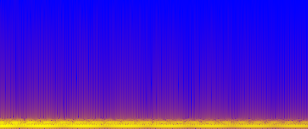

In [15]:
// Synthesize drum strikes by projecting a 2D mallet hit onto each drum's actual eigenvectors!
const int numSynthModes = 28;
const double baseFreqHz = 220.0; // Equal-pitch fundamental (A3 = 220 Hz)
final double refLambda0 = circleLambdas.getCell([0]);

NDArray<Float64> synthesizeDrumStrike({
  required NDArray<Float64> eigenvalues,
  required NDArray<Float64> eigenvectors,
  required NDArray<Boolean> mask,
  required double xStrike,
  required double yStrike,
  required double durationSec,
  required bool sameMembraneTension,
  double malletSharpness = 55.0,
}) {
  return NDArray.scope(() {
    final int nSamp = (sampleRate * durationSec).round();
    final tVec = linspace(0.0, durationSec, nSamp, endpoint: false, dtype: DType.float64);

    // 1. Build a 2D Gaussian mallet strike at (xStrike, yStrike) and extract interior mask points
    final distSqStrike = (xCoord - xStrike) * (xCoord - xStrike) +
        (yCoord - yStrike) * (yCoord - yStrike);
    final mallet2D = exp(distSqStrike * (-malletSharpness));
    final malletInterior = mallet2D[mask] as NDArray<Float64>;
    final nDof = malletInterior.shape[0];
    final nModes = math.min(numSynthModes, nDof);

    // 2. Project the mallet strike onto the first nModes eigenvectors via matmul()!
    final eigVecsM = eigenvectors.slice([Slice.all(), Slice(stop: nModes)]);
    final rawCoupling = abs(matmul(malletInterior.reshape([1, nDof]), eigVecsM).flatten());
    final maxCoupling = max(rawCoupling).scalar;
    final normCoupling = rawCoupling * (1.0 / (maxCoupling > 1e-12 ? maxCoupling : 1.0));

    // Emphasize overtones (like a crisp rim strike) so the overtone chord rings out clearly
    final modeIndex = linspace(0.0, (nModes - 1).toDouble(), nModes, dtype: DType.float64);
    final overtoneBoost = ((exp(modeIndex * -0.8) * -1.0) + 1.0) * 0.95 + 0.45;
    final weights = (normCoupling * overtoneBoost).reshape([1, nModes]);

    // 3. Compute mode frequencies (either physical same-membrane pitch or equal 220 Hz fundamental)
    final lambdasM = eigenvalues.slice([Slice(stop: nModes)]);
    final freqRatios = sqrt(lambdasM * (1.0 / lambdasM.getCell([0])));
    final freqsHz = sameMembraneTension
        ? sqrt(lambdasM * (1.0 / refLambda0)) * 140.0
        : freqRatios * baseFreqHz;

    // 4. Broadcast [nModes, 1] frequencies against [1, nSamp] time vector with sustained overtones
    final omegaCol = (freqsHz * (2.0 * math.pi)).reshape([nModes, 1]);
    final dampCol  = ((freqRatios - 1.0) * 0.38 + 0.85).reshape([nModes, 1]);
    final tRow     = tVec.reshape([1, nSamp]);

    // Fast 4ms mallet attack envelope + long resonant decay
    final attackEnv = (exp(tRow * -350.0) * -1.0) + 1.0;
    final modeWaves = sin(omegaCol * tRow) * exp((dampCol * -1.0) * tRow) * attackEnv;
    final rawSignal = matmul(weights, modeWaves).flatten();

    final maxAmp = max(abs(rawSignal)).scalar;
    return (rawSignal * (0.88 / (maxAmp > 1e-12 ? maxAmp : 1.0))).detachToParentScope();
  });
}

// --- PART A: One-Click "Same Membrane Tension" Sequential Tour (0.95s per drum) ---
final tourGap = NDArray.zeros([(sampleRate * 0.12).round()], DType.float64);
final sameMembraneTour = concatenate([
  synthesizeDrumStrike(eigenvalues: circleLambdas,  eigenvectors: circleModes,  mask: circleMask,  xStrike: -0.48, yStrike: 0.28,  durationSec: 0.90, sameMembraneTension: true),
  tourGap,
  synthesizeDrumStrike(eigenvalues: lShapeLambdas,  eigenvectors: lShapeModes,  mask: lShapeMask,  xStrike: 0.45,  yStrike: -0.45, durationSec: 0.90, sameMembraneTension: true),
  tourGap,
  synthesizeDrumStrike(eigenvalues: stadiumLambdas, eigenvectors: stadiumModes, mask: stadiumMask, xStrike: -0.52, yStrike: 0.24,  durationSec: 0.90, sameMembraneTension: true),
  tourGap,
  synthesizeDrumStrike(eigenvalues: peanutLambdas,  eigenvectors: peanutModes,  mask: peanutMask,  xStrike: -0.55, yStrike: 0.00,  durationSec: 0.90, sameMembraneTension: true, malletSharpness: 18.0),
  tourGap,
  synthesizeDrumStrike(eigenvalues: ellipseLambdas, eigenvectors: ellipseModes, mask: ellipseMask, xStrike: -0.58, yStrike: 0.12,  durationSec: 0.90, sameMembraneTension: true),
  tourGap,
  synthesizeDrumStrike(eigenvalues: ringLambdas,    eigenvectors: ringModes,    mask: ringMask,    xStrike: -0.68, yStrike: 0.28,  durationSec: 0.90, sameMembraneTension: true),
]);

display(Markdown('### 🎧 Tour 1 (Click Play!): All 6 Drums Carved from the *Same Membrane* (True Physical Pitch + Timbre)\n'
    '**Order:** `1. Circle (Deep Bass)` → `2. L-Shape` → `3. Stadium` → `4. Peanut (Pulsing Bongo)` → `5. Slender Ellipse (High Bar)` → `6. Annular Ring (High Metallic Chime)`'));
display(Audio(sameMembraneTour, sampleRate: sampleRate));

// --- PART B: Equal-Pitch (f₁ = 220 Hz) Pure Overtone Timbre Comparison (1.8s each) ---
const double clipDur = 1.8;
final int numSamples = (sampleRate * clipDur).round();

final NDArray<Float64> circleAudio  = synthesizeDrumStrike(eigenvalues: circleLambdas,  eigenvectors: circleModes,  mask: circleMask,  xStrike: -0.48, yStrike: 0.28,  durationSec: clipDur, sameMembraneTension: false);
final NDArray<Float64> ellipseAudio = synthesizeDrumStrike(eigenvalues: ellipseLambdas, eigenvectors: ellipseModes, mask: ellipseMask, xStrike: -0.58, yStrike: 0.12,  durationSec: clipDur, sameMembraneTension: false);
final NDArray<Float64> ringAudio    = synthesizeDrumStrike(eigenvalues: ringLambdas,    eigenvectors: ringModes,    mask: ringMask,    xStrike: -0.68, yStrike: 0.28,  durationSec: clipDur, sameMembraneTension: false);
final NDArray<Float64> lShapeAudio  = synthesizeDrumStrike(eigenvalues: lShapeLambdas,  eigenvectors: lShapeModes,  mask: lShapeMask,  xStrike: 0.45,  yStrike: -0.45, durationSec: clipDur, sameMembraneTension: false);
final NDArray<Float64> stadiumAudio = synthesizeDrumStrike(eigenvalues: stadiumLambdas, eigenvectors: stadiumModes, mask: stadiumMask, xStrike: -0.52, yStrike: 0.24,  durationSec: clipDur, sameMembraneTension: false);
final NDArray<Float64> peanutAudio  = synthesizeDrumStrike(eigenvalues: peanutLambdas,  eigenvectors: peanutModes,  mask: peanutMask,  xStrike: -0.55, yStrike: 0.00,  durationSec: clipDur, sameMembraneTension: false, malletSharpness: 16.0);

final equalPitchTour = concatenate([
  circleAudio.slice([Slice(stop: (sampleRate * 1.05).round())]),
  tourGap,
  ellipseAudio.slice([Slice(stop: (sampleRate * 1.05).round())]),
  tourGap,
  ringAudio.slice([Slice(stop: (sampleRate * 1.05).round())]),
  tourGap,
  lShapeAudio.slice([Slice(stop: (sampleRate * 1.05).round())]),
  tourGap,
  stadiumAudio.slice([Slice(stop: (sampleRate * 1.05).round())]),
  tourGap,
  peanutAudio.slice([Slice(stop: (sampleRate * 1.05).round())]),
]);

display(Markdown('### 🎧 Tour 2 (Click Play!): All 6 Drums Retuned to the *Exact Same Fundamental* (f₁ = 220 Hz — Pure Overtone Chord Comparison)\n'
    '**Order:** `1. Circle` → `2. Slender Ellipse` → `3. Annular Ring (Gong)` → `4. L-Shape` → `5. Stadium` → `6. Peanut (Listen for the wah-wah-wah beating!)`'));
display(Audio(equalPitchTour, sampleRate: sampleRate));

display(Markdown('---\n### Individual Drum Players & Spectrograms (f₁ = 220 Hz)'));

display(Markdown('#### 🥁 1. Circular Drum — Wide Bessel Overtones (1.00×, 1.59×, 2.12×, 2.29×)'));
display(Audio(circleAudio, sampleRate: sampleRate));
display(Spectrogram(circleAudio, sampleRate: sampleRate, title: 'Circular Drum Spectrogram (Widely Spaced Bessel Overtones)'));

display(Markdown('#### 🥁 2. Slender Elliptical Drum — Woody Marimba-Bar Progression (1.00×, 1.15×, 1.35×, 1.59×)'));
display(Audio(ellipseAudio, sampleRate: sampleRate));

display(Markdown('#### 🥁 3. Annular Ring (Gong Rim) Drum — Shimmering Metallic Bell Cluster (1.00×, 1.04×, 1.15×, 1.31×)'));
display(Audio(ringAudio, sampleRate: sampleRate));
display(Spectrogram(ringAudio, sampleRate: sampleRate, title: 'Annular Ring Spectrogram (Dense Metallic Cluster Near 220-350 Hz)'));

display(Markdown('#### 🥁 4. L-Shaped Drum — Corner-Diffracted Asymmetric Overtones'));
display(Audio(lShapeAudio, sampleRate: sampleRate));

display(Markdown('#### 🥁 5. Stadium (Capsule) Drum — Wave-Chaos Timbre'));
display(Audio(stadiumAudio, sampleRate: sampleRate));

display(Markdown('#### 🥁 6. Peanut Twin-Bell Drum — Coupled-Oscillator "Wah-Wah-Wah" Beating!'));
display(Audio(peanutAudio, sampleRate: sampleRate));
Spectrogram(peanutAudio, sampleRate: sampleRate, title: 'Peanut Drum Spectrogram (Notice the Rhythmic Pulsing / Beating Between Modes 1 & 2!)')

### Step 9b: Recovering the Drum's Eigenfrequencies from Sound (`rfft` and `rfftfreq`)

Finally, let's pretend someone handed us **only** the audio recording `circleAudio` and asked: *"What were the resonant frequencies of that drum?"*

We pass `circleAudio` into **`rfft`** (the Real Fast Fourier Transform, powered by PocketFFT) and compute the frequency axis in Hz using **`rfftfreq`**. The peaks of the FFT spectrum `abs(fftCoeffs)` line up right on top of the theoretical eigenvalues $f_1 \sqrt{\lambda_k / \lambda_1}$!

In [16]:
// Apply the Real Fast Fourier Transform (rfft) to our Circular Drum audio signal
final fftPlot = NDArray.scope(() {
  final fftCoeffs = rfft(circleAudio);
  final freqsHz   = rfftfreq(numSamples, d: 1.0 / sampleRate);

  // Slice the spectrum to the 0 - 850 Hz frequency band using a boolean mask
  final lowBandMask = freqsHz <= 850.0;
  final bandFreqs = freqsHz[lowBandMask] as NDArray<Float64>;
  final bandMag   = abs(fftCoeffs[lowBandMask] as NDArray<Complex128>);

  final cL0 = circleLambdas.getCell([0]);
  final expectedPeaks = [
    for (var k = 0; k < 6; k++)
      '${(baseFreqHz * math.sqrt(circleLambdas.getCell([k]) / cL0)).toStringAsFixed(1)} Hz',
  ];
  print('Expected Circular Drum Eigenfrequencies: ${expectedPeaks.join(", ")}');

  return Plot(
    x: bandFreqs.detachToParentScope(),
    y: bandMag.detachToParentScope(),
    title: 'Real FFT Spectrum of Circular Drum Audio (Peaks Match Eigenfrequencies!)',
    color: '#f38ba8',
  );
});

fftPlot

Expected Circular Drum Eigenfrequencies: 220.0 Hz, 349.8 Hz, 349.8 Hz, 466.2 Hz, 468.7 Hz, 501.9 Hz

[{"mimeType":"text/plain","data":"Expected Circular Drum Eigenfrequencies: 220.0 Hz, 349.8 Hz, 349.8 Hz, 466.2 Hz, 468.7 Hz, 501.9 Hz"},{"mimeType":"text/html","data":"<div class=\"plot-container\" style=\"background: #181825; border: 1px solid #45475a; border-radius: 8px; padding: 16px; display: inline-block; font-family: system-ui, sans-serif;\">\n  <div style=\"font-weight: bold; margin-bottom: 8px; color: #cdd6f4; font-size: 1.1em;\">Real FFT Spectrum of Circular Drum Audio (Peaks Match Eigenfrequencies!)</div>\n  <svg width=\"500.0\" height=\"280.0\" viewBox=\"0 0 500.0 280.0\" style=\"overflow: visible;\">\n    <line x1=\"40.0\" y1=\"240.0\" x2=\"460.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <line x1=\"40.0\" y1=\"40.0\" x2=\"40.0\" y2=\"240.0\" stroke=\"#45475a\" stroke-width=\"1\"/>\n    <polyline fill=\"none\" stroke=\"#f38ba8\" stroke-width=\"2.5\" points=\"40.0,240.0 40.3,240.0 40.5,240.0 40.8,240.0 41.1,240.0 41.4,240.0 41.6,240.0 41.9,240.0 42.2,240.0 42.5,240.0 42.7,240.0 43.0,240.0 43.3,240.0 43.6,240.0 43.8,240.0 44.1,240.0 44.4,240.0 44.7,240.0 44.9,240.0 45.2,240.0 45.5,240.0 45.8,240.0 46.0,240.0 46.3,240.0 46.6,240.0 46.9,240.0 47.1,240.0 47.4,240.0 47.7,240.0 48.0,240.0 48.2,240.0 48.5,240.0 48.8,240.0 49.1,240.0 49.3,240.0 49.6,240.0 49.9,240.0 50.2,240.0 50.4,240.0 50.7,240.0 51.0,240.0 51.3,240.0 51.5,240.0 51.8,240.0 52.1,240.0 52.4,240.0 52.6,240.0 52.9,240.0 53.2,240.0 53.5,240.0 53.7,240.0 54.0,240.0 54.3,240.0 54.5,240.0 54.8,240.0 55.1,240.0 55.4,240.0 55.6,240.0 55.9,240.0 56.2,240.0 56.5,240.0 56.7,240.0 57.0,240.0 57.3,240.0 57.6,240.0 57.8,240.0 58.1,240.0 58.4,240.0 58.7,240.0 58.9,240.0 59.2,240.0 59.5,240.0 59.8,240.0 60.0,240.0 60.3,240.0 60.6,240.0 60.9,240.0 61.1,240.0 61.4,240.0 61.7,240.0 62.0,240.0 62.2,240.0 62.5,240.0 62.8,240.0 63.1,240.0 63.3,240.0 63.6,240.0 63.9,240.0 64.2,240.0 64.4,240.0 64.7,240.0 65.0,240.0 65.3,240.0 65.5,240.0 65.8,240.0 66.1,240.0 66.4,240.0 66.6,240.0 66.9,240.0 67.2,240.0 67.5,240.0 67.7,240.0 68.0,240.0 68.3,240.0 68.5,240.0 68.8,240.0 69.1,240.0 69.4,240.0 69.6,240.0 69.9,240.0 70.2,240.0 70.5,240.0 70.7,240.0 71.0,240.0 71.3,240.0 71.6,240.0 71.8,240.0 72.1,240.0 72.4,240.0 72.7,240.0 72.9,240.0 73.2,240.0 73.5,240.0 73.8,240.0 74.0,240.0 74.3,240.0 74.6,240.0 74.9,240.0 75.1,240.0 75.4,240.0 75.7,240.0 76.0,240.0 76.2,240.0 76.5,240.0 76.8,240.0 77.1,240.0 77.3,240.0 77.6,240.0 77.9,240.0 78.2,240.0 78.4,240.0 78.7,240.0 79.0,240.0 79.3,240.0 79.5,240.0 79.8,240.0 80.1,240.0 80.4,240.0 80.6,240.0 80.9,240.0 81.2,240.0 81.5,240.0 81.7,240.0 82.0,240.0 82.3,240.0 82.5,240.0 82.8,240.0 83.1,240.0 83.4,240.0 83.6,239.9 83.9,239.9 84.2,239.9 84.5,239.9 84.7,239.9 85.0,239.9 85.3,239.9 85.6,239.9 85.8,239.9 86.1,239.9 86.4,239.9 86.7,239.9 86.9,239.9 87.2,239.9 87.5,239.9 87.8,239.9 88.0,239.9 88.3,239.9 88.6,239.9 88.9,239.9 89.1,239.9 89.4,239.9 89.7,239.9 90.0,239.9 90.2,239.9 90.5,239.9 90.8,239.9 91.1,239.9 91.3,239.9 91.6,239.9 91.9,239.9 92.2,239.9 92.4,239.9 92.7,239.9 93.0,239.9 93.3,239.9 93.5,239.9 93.8,239.9 94.1,239.9 94.4,239.9 94.6,239.9 94.9,239.9 95.2,239.9 95.5,239.9 95.7,239.9 96.0,239.9 96.3,239.9 96.5,239.9 96.8,239.9 97.1,239.9 97.4,239.9 97.6,239.9 97.9,239.9 98.2,239.9 98.5,239.9 98.7,239.9 99.0,239.9 99.3,239.9 99.6,239.9 99.8,239.9 100.1,239.9 100.4,239.9 100.7,239.9 100.9,239.9 101.2,239.9 101.5,239.9 101.8,239.9 102.0,239.9 102.3,239.9 102.6,239.9 102.9,239.9 103.1,239.9 103.4,239.9 103.7,239.9 104.0,239.9 104.2,239.9 104.5,239.9 104.8,239.9 105.1,239.9 105.3,239.9 105.6,239.9 105.9,239.9 106.2,239.9 106.4,239.9 106.7,239.9 107.0,239.9 107.3,239.9 107.5,239.9 107.8,239.9 108.1,239.9 108.4,239.9 108.6,239.9 108.9,239.9 109.2,239.9 109.5,239.9 109.7,239.9 110.0,239.9 110.3,239.9 110.5,239.9 110.8,239.9 111.1,239.9 111.4,239.9 111.6,239.9 111.9,239.9 112.2,239.9 112.5,239.8 112.7,239.8 113.0,239.8 113.3,239.8 113.6,239.8 113.8,239.8 114.1,239.8 114.4,239.8 114.7,239.8 114.9,239.8 115.2,239.8 115.5,239.8 115.8,2